# Đề 6 — Classification: Book Recommendation Dataset

## Định nghĩa bài toán

Dự đoán một lượt đánh giá sách thuộc nhóm điểm cao (8–10)
hay nhóm chưa đạt mức điểm cao (1–7), dựa trên thông tin
người dùng và sách.

Chỉ xét các lượt đánh giá có điểm từ 1–10. Nhóm quy ước:
- `liked = 1`: điểm 8–10 — nhóm đánh giá cao.
- `liked = 0`: điểm 1–7 — nhóm chưa đạt mức đánh giá cao.

Ngưỡng 8 do nhóm lựa chọn để phân biệt các đánh giá ở vùng
điểm cao của thang 1–10. Đây là quy ước của bài toán,
không phải ngưỡng được đề bài quy định.

Điểm 0 không được gán vào hai nhãn trên và được loại khỏi
tập dữ liệu phân loại.

In [2]:
# Nhập thư viện: Path xử lý đường dẫn; pandas xử lý bảng; numpy hỗ trợ tính toán; display hiển thị bảng.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from scipy.stats import mannwhitneyu
from IPython.display import display
# Chọn thư mục chứa dữ liệu CSV; kiểm tra thư mục tồn tại trước khi đọc.
DATA_DIR = Path("DATA_SET")
assert DATA_DIR.is_dir(), "Cần đặt thư mục DATA_SET trong thư mục làm việc hoặc sửa DATA_DIR."


## 1. Data Inspection
Đọc tự động ba bảng CSV. Kiểm tra UTF-8 bằng chế độ strict trên toàn bộ tệp; giữ ISBN dạng chuỗi để bảo toàn số 0 đầu và ký tự X. Ba bảng khác cấu trúc nên dùng merge thay vì concat.

In [3]:
# Tạo từ điển lưu ba bảng dữ liệu theo tên Books, Users và Ratings.
tables = {}

# Lần lượt đọc từng tệp CSV trong thư mục dữ liệu.
for name in ["Books", "Users", "Ratings"]:
    path = DATA_DIR / f"{name}.csv"
    # Đọc toàn bộ tệp với UTF-8 strict để phát hiện lỗi mã hóa; pass chỉ bỏ qua nội dung từng dòng.
    with path.open(encoding="utf-8", errors="strict") as stream:
        for _ in stream:
            pass
    # Nạp CSV vào DataFrame; giữ ISBN dạng chuỗi để không mất số 0 đầu hoặc ký tự X.
    tables[name] = pd.read_csv(path, encoding="utf-8", dtype={"ISBN": "string"}, low_memory=False)

# Lấy ba DataFrame từ từ điển để dùng ở các bước sau.
books, users, ratings = [tables[n] for n in ["Books", "Users", "Ratings"]]

# Tóm tắt mỗi bảng: shape[0] là số dòng, shape[1] là số cột; duplicated đánh dấu dòng trùng.
summary = pd.DataFrame([{"Bảng": n, "Số dòng": d.shape[0], "Số cột": d.shape[1], "Dòng trùng": int(d.duplicated().sum())} for n,d in tables.items()])
display(summary)

# Hiển thị kiểu dữ liệu và số ô thiếu của từng cột trong mỗi bảng.
for name, frame in tables.items():
    print("\n", name)
    # dtypes lấy kiểu từng cột; astype(str) chuyển thông tin kiểu thành chuỗi, không đổi dữ liệu gốc.
    display(pd.DataFrame({"Kiểu": frame.dtypes.astype(str), "Thiếu": frame.isna().sum()}))


,Bảng,Số dòng,Số cột,Dòng trùng
0,Books,271360,8,0
1,Users,278858,3,0
2,Ratings,1149780,3,0



 Books


,Kiểu,Thiếu
ISBN,string,0
Book-Title,str,0
Book-Author,str,2
Year-Of-Publication,str,0
Publisher,str,2
Image-URL-S,str,0
Image-URL-M,str,0
Image-URL-L,str,3



 Users


,Kiểu,Thiếu
User-ID,int64,0
Location,str,0
Age,float64,110762



 Ratings


,Kiểu,Thiếu
User-ID,int64,0
ISBN,string,0
Book-Rating,int64,0


In [4]:
# Kiểm tra khóa ISBN và User-ID không bị thiếu và không trùng; assert báo lỗi nếu điều kiện sai.
assert books["ISBN"].notna().all() and books["ISBN"].is_unique
assert users["User-ID"].notna().all() and users["User-ID"].is_unique

# Đếm các dòng đánh giá trùng cặp người dùng–sách.
print("Trùng cặp User-ID, ISBN:", ratings.duplicated(["User-ID", "ISBN"]).sum())

# isin kiểm tra ISBN có trong bảng sách; ~ đảo kết quả; sum đếm các đánh giá không tìm thấy sách.
print("Đánh giá thiếu sách:", (~ratings["ISBN"].isin(books["ISBN"])).sum())

# Đếm các đánh giá có User-ID không xuất hiện trong bảng người dùng.
print("Đánh giá thiếu người dùng:", (~ratings["User-ID"].isin(users["User-ID"])).sum())

# Đếm số lượt cho từng mức điểm.
display(ratings.groupby("Book-Rating").size().rename("Số lượt").to_frame())

# Chuyển năm xuất bản sang số; errors="coerce" biến giá trị không chuyển được thành NaN.
year = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")

# loc chọn những dòng có năm thiếu hoặc không chuyển được thành số và các cột cần xem xét.
display(books.loc[year.isna(), ["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication", "Publisher"]])

# Kiểm tra tuổi nhỏ nhất và lớn nhất để phát hiện giá trị bất thường, ví dụ 0 hoặc 244.
print("Tuổi nhỏ nhất/lớn nhất:", users["Age"].min(), users["Age"].max())


Trùng cặp User-ID, ISBN: 0
Đánh giá thiếu sách: 118644
Đánh giá thiếu người dùng: 0


,Số lượt
Book-Rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher
209538,078946697X,"DK Readers: Creating the X-Men, How It All Beg...",2000,DK Publishing Inc,http://images.amazon.com/images/P/078946697X.0...
220731,2070426769,"Peuple du ciel, suivi de 'Les Bergers\"";Jean-M...",2003,Gallimard,http://images.amazon.com/images/P/2070426769.0...
221678,0789466953,"DK Readers: Creating the X-Men, How Comic Book...",2000,DK Publishing Inc,http://images.amazon.com/images/P/0789466953.0...


Tuổi nhỏ nhất/lớn nhất: 0.0 244.0


## 2. Data Loading and Integration
Ratings là bảng trung tâm, mỗi dòng là một lượt đánh giá. Ratings có quan hệ nhiều–một với Users qua cột User-ID và với Books qua cột ISBN: một người dùng có thể có nhiều lượt đánh giá, một sách có thể được đánh giá nhiều lần. Dùng left join để giữ toàn bộ lượt đánh giá, kể cả khi không tìm thấy người dùng hoặc sách tương ứng. Tham số `validate='many_to_one'` kiểm tra khóa ở bảng Users hoặc Books không bị trùng; nếu bị trùng thì báo lỗi để tránh ghép làm tăng số dòng. Chỉ ghép các cột cần phân tích để giảm bộ nhớ.

In [5]:
# Chọn các cột thông tin sách cần ghép để giảm bộ nhớ.
book_columns = ["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication", "Publisher"]

# Ghép đánh giá với sách theo ISBN; left giữ mọi đánh giá, Tham số `validate='many_to_one'` kiểm tra khóa ở bảng Users hoặc Books không bị trùng; nếu bị trùng thì báo lỗi để tránh ghép làm tăng số dòng. Chỉ ghép các cột cần phân tích để giảm bộ nhớ.; indicator ghi trạng thái khớp của mỗi lần ghép
integrated_raw = ratings.merge(books[book_columns], on="ISBN", how="left", validate="many_to_one", indicator="book_match")

# Ghép tiếp người dùng theo User-ID
integrated_raw = integrated_raw.merge(users, on="User-ID", how="left", validate="many_to_one", indicator="user_match")

# Đảm bảo việc ghép không làm thay đổi số dòng đánh giá.
assert len(integrated_raw) == len(ratings)

# Xem kích thước bảng ghép và số dòng khớp/không khớp với từng bảng phụ.
print("Kích thước bảng ghép:", integrated_raw.shape)
display(integrated_raw["book_match"].value_counts())
display(integrated_raw["user_match"].value_counts())
display(integrated_raw.head())


Kích thước bảng ghép: (1149780, 11)


book_match
both          1031136
left_only      118644
right_only          0
Name: count, dtype: int64

user_match
both          1149780
left_only           0
right_only          0
Name: count, dtype: int64

,User-ID,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,book_match,Location,Age,user_match
0,276725,034545104X,0,Flesh Tones: A Novel,M. J. Rose,2002,Ballantine Books,both,"tyler, texas, usa",NaN,both
1,276726,0155061224,5,Rites of Passage,Judith Rae,2001,Heinle,both,"seattle, washington, usa",NaN,both
2,276727,0446520802,0,The Notebook,Nicholas Sparks,1996,Warner Books,both,"h, new south wales, australia",16.0,both
3,276729,052165615X,3,Help!: Level 1,Philip Prowse,1999,Cambridge University Press,both,"rijeka, n/a, croatia",16.0,both
4,276729,0521795028,6,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001,Cambridge University Press,both,"rijeka, n/a, croatia",16.0,both


## 3. Data Cleaning
- Bỏ dòng trùng hoàn toàn; nếu còn nhiều điểm khác nhau cho cùng cặp người dùng–sách thì dừng để xem xét, không tự chọn một điểm.
- Loại riêng 3 dòng sách có năm không phải số khỏi bảng phân tích vì có dấu hiệu lệch trường; không suy đoán để sửa. Các đánh giá liên quan vẫn ở bảng ghép, được đánh dấu không có metadata sách sạch.
- Quy ước tuổi hợp lệ 5–100 và năm xuất bản 1450–2026; đây là ngưỡng đề xuất, không phải kết luận mọi giá trị ngoài khoảng đều sai. Năm 0 coi là chưa biết. Giữ giá trị thiếu dạng số, tạo cờ thiếu; chưa điền median trước khi chia train/test để tránh rò rỉ dữ liệu.
- Điền Unknown cho tác giả, nhà xuất bản và vị trí thiếu/rỗng; chuẩn hóa khoảng trắng. ISBN luôn là chuỗi.
- Giữ điểm 0 ở bảng tổng hợp. Với tập phân loại đề xuất, chỉ lấy điểm 1–10 và đặt liked = 1 nếu điểm ≥ 8. Ý nghĩa của điểm 0 cần xác nhận theo mô tả dataset; không tự gán 0 thành nhãn không thích.


In [6]:
# Bỏ các dòng trùng hoàn toàn và tạo bản sao để giữ nguyên ba bảng gốc.
books_clean = books.drop_duplicates().copy()
users_clean = users.drop_duplicates().copy()
ratings_clean = ratings.drop_duplicates().copy()


# Kiểm tra khóa sách duy nhất và không còn cặp người dùng–sách trùng cần xem xét.
assert books_clean["ISBN"].is_unique
assert not ratings_clean.duplicated(["User-ID", "ISBN"]).any(), "Cần xem xét đánh giá xung đột."


# Chuyển năm sang số; giá trị thiếu hoặc không chuyển được sẽ thành NaN.
parsed_year = pd.to_numeric(books_clean["Year-Of-Publication"], errors="coerce")


# Tách riêng các dòng có năm không chuyển được hoặc bị thiếu; loc lọc dòng theo điều kiện.
books_quarantine = books_clean.loc[parsed_year.isna()].copy()
books_clean = books_clean.loc[parsed_year.notna()].copy()


# Chuyển lại cột năm của bảng sách còn giữ để chuẩn hóa kiểu số.
y = pd.to_numeric(books_clean["Year-Of-Publication"], errors="coerce")
# Chỉ giữ năm 1450–2026; where thay các năm ngoài khoảng (kể cả 0) bằng giá trị thiếu.
books_clean["Year-Of-Publication"] = y.where(y.between(1450, 2026)).astype("Int64")
# Đánh giấu các năm nằm ngoài khoảng bị gán giá trị là NA
books_clean["Year_missing"] = books_clean["Year-Of-Publication"].isna()


# Chuyển tuổi sang số; giá trị không chuyển được thành giá trị thiếu.
a = pd.to_numeric(users_clean["Age"], errors="coerce")
# Theo quy ước của bài, chỉ giữ tuổi 5–100; tuổi như 244 thành <NA>, không xóa dòng người dùng.
users_clean["Age"] = a.where(a.between(5, 100)).astype("Float64")
# Đánh giấy người có tuổi ngoài khoảng hoặc bị thiếu  bị gán giá trị là NA
users_clean["Age_missing"] = users_clean["Age"].isna()


# Làm sạch các cột chữ: bỏ khoảng trắng ở hai đầu, đổi chuỗi rỗng thành thiếu rồi điền Unknown.
for frame, cols in [(books_clean, ["Book-Title", "Book-Author", "Publisher"]), (users_clean, ["Location"])]:
    for col in cols:
        frame[col] = frame[col].astype("string").str.strip().replace("", pd.NA).fillna("Unknown")
# Chuẩn hóa User-ID thành số nguyên ở cả hai bảng; errors="raise" báo lỗi nếu không chuyển được.
for frame in [users_clean, ratings_clean]:
    frame["User-ID"] = pd.to_numeric(frame["User-ID"], errors="raise").astype("int64")


# Chuyển điểm đánh giá sang số; kiểm tra mọi điểm nằm trong khoảng 0–10 và là số nguyên.
ratings_clean["Book-Rating"] = pd.to_numeric(ratings_clean["Book-Rating"], errors="raise")
assert ratings_clean["Book-Rating"].between(0, 10).all()
assert (ratings_clean["Book-Rating"] % 1 == 0).all()

# Lưu điểm bằng int8 vì khoảng 0–10 nhỏ, giúp tiết kiệm bộ nhớ.
ratings_clean["Book-Rating"] = ratings_clean["Book-Rating"].astype("int8")
# Báo số sách tách riêng, số tuổi thiếu và số năm thiếu sau khi làm sạch.
print("Sách tách riêng:", len(books_quarantine))
print("Tuổi thiếu sau xử lý:", users_clean["Age_missing"].sum())
print("Năm thiếu sau xử lý:", books_clean["Year_missing"].sum())


Sách tách riêng: 3
Tuổi thiếu sau xử lý: 112010
Năm thiếu sau xử lý: 4631


In [7]:
# Ghép lại các bảng đã làm sạch; left vẫn giữ các đánh giá chưa tìm thấy thông tin sách sạch.
data_clean = ratings_clean.merge(books_clean[book_columns + ["Year_missing"]], on="ISBN", how="left", validate="many_to_one", indicator="book_match")
data_clean = data_clean.merge(users_clean, on="User-ID", how="left", validate="many_to_one", indicator="user_match")

# Kiểm tra bảng ghép giữ nguyên số đánh giá và không sinh cặp người dùng–sách trùng.
assert len(data_clean) == len(ratings_clean)
assert not data_clean.duplicated(["User-ID", "ISBN"]).any()

# Cập nhật cờ thiếu sau khi ghép, kể cả các dòng không khớp bảng sách/người dùng.
data_clean["Year_missing"] = data_clean["Year-Of-Publication"].isna()
data_clean["Age_missing"] = data_clean["Age"].isna()

# Tạo tập phân loại chỉ từ điểm 1–10; điểm 0 vẫn được giữ trong data_clean.
classification_data = data_clean.loc[data_clean["Book-Rating"].between(1, 10)].copy()


# Tạo nhãn liked:
# 1 = đánh giá cao (điểm 8–10).
# 0 = chưa đạt mức đánh giá cao (điểm 1–7).
classification_data["liked"] = (classification_data["Book-Rating"] >= 8).astype("int8")


# Xem kích thước dữ liệu và số đánh giá không có thông tin sách sạch (left_only).
print("Bảng sạch:", data_clean.shape)
print("Lượt đánh giá chưa có metadata sách sạch:", data_clean["book_match"].eq("left_only").sum())
print("Tập phân loại đề xuất:", classification_data.shape)

# Đếm số mẫu ở mỗi nhãn 0 và 1 để xem phân bố nhãn.
print(classification_data["liked"].value_counts().sort_index().to_string())

# Hiển thị 5 dòng đầu của bảng sạch để kiểm tra kết quả.
display(data_clean.head())
display(classification_data.head())


Bảng sạch: (1149780, 13)
Lượt đánh giá chưa có metadata sách sạch: 118648
Tập phân loại đề xuất: (433671, 14)
liked
0    183784
1    249887


,User-ID,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,Year_missing,book_match,Location,Age,Age_missing,user_match
0,276725,034545104X,0,Flesh Tones: A Novel,M. J. Rose,2002,Ballantine Books,False,both,"tyler, texas, usa",<NA>,True,both
1,276726,0155061224,5,Rites of Passage,Judith Rae,2001,Heinle,False,both,"seattle, washington, usa",<NA>,True,both
2,276727,0446520802,0,The Notebook,Nicholas Sparks,1996,Warner Books,False,both,"h, new south wales, australia",16.0,False,both
3,276729,052165615X,3,Help!: Level 1,Philip Prowse,1999,Cambridge University Press,False,both,"rijeka, n/a, croatia",16.0,False,both
4,276729,0521795028,6,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001,Cambridge University Press,False,both,"rijeka, n/a, croatia",16.0,False,both


,User-ID,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,Year_missing,book_match,Location,Age,Age_missing,user_match,liked
1,276726,0155061224,5,Rites of Passage,Judith Rae,2001,Heinle,False,both,"seattle, washington, usa",<NA>,True,both,0
3,276729,052165615X,3,Help!: Level 1,Philip Prowse,1999,Cambridge University Press,False,both,"rijeka, n/a, croatia",16.0,False,both,0
4,276729,0521795028,6,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001,Cambridge University Press,False,both,"rijeka, n/a, croatia",16.0,False,both,0
6,276736,3257224281,8,<NA>,<NA>,<NA>,<NA>,True,left_only,"salzburg, salzburg, austria",<NA>,True,both,1
7,276737,0600570967,6,<NA>,<NA>,<NA>,<NA>,True,left_only,"sydney, new south wales, australia",14.0,False,both,0


In [8]:
# Thống kê thiếu riêng trong tập phân loại sau khi ghép dữ liệu sạch.
missing_summary = pd.DataFrame({
    "Số giá trị thiếu": classification_data.isna().sum(),
    "Tỷ lệ thiếu (%)": classification_data.isna().mean() * 100
})
print("Giá trị thiếu trong tập phân loại sau khi ghép:")
display(missing_summary.round(2))

# Phân biệt thiếu metadata do không khớp sách với thiếu từng trường dữ liệu.
missing_book_count = classification_data["book_match"].eq("left_only").sum()
missing_book_percentage = missing_book_count / len(classification_data) * 100
print(f"Lượt đánh giá không có metadata sách sạch: {missing_book_count:,} ({missing_book_percentage:.2f}%)")

# Các cờ thiếu phải đầy đủ và phản ánh đúng dữ liệu sau khi ghép.
assert classification_data["Year_missing"].equals(classification_data["Year-Of-Publication"].isna())
assert classification_data["Age_missing"].equals(classification_data["Age"].isna())


Giá trị thiếu trong tập phân loại sau khi ghép:


,Số giá trị thiếu,Tỷ lệ thiếu (%)
User-ID,0,0.00
ISBN,0,0.00
Book-Rating,0,0.00
Book-Title,49830,11.49
Book-Author,49830,11.49
Year-Of-Publication,55636,12.83
Publisher,49830,11.49
Year_missing,0,0.00
book_match,0,0.00
Location,0,0.00


Lượt đánh giá không có metadata sách sạch: 49,830 (11.49%)


### Giá trị thiếu sau khi ghép dữ liệu

Left join giữ lại các lượt đánh giá không tìm thấy sách tương ứng, nên metadata sách có thể bị thiếu sau khi ghép dù các cột chữ trong bảng sách đã được điền `Unknown`. Bảng trên thống kê riêng số lượng và tỷ lệ thiếu trong `classification_data`.

Nhóm giữ các lượt đánh giá này và cập nhật `Year_missing`, `Age_missing` theo dữ liệu sau khi ghép. Cờ `Year_missing = True` biểu thị thiếu năm xuất bản; cột `book_match` giúp phân biệt trường hợp không khớp sách.

**Cách xử lý dự kiến khi xây dựng mô hình:**

- Với biến số được chọn làm đầu vào: điền giá trị thiếu bằng median tính trên tập train.
- Với biến phân loại được chọn làm đầu vào: điền giá trị thiếu bằng `Unknown`.
- Áp dụng cùng cách xử lý cho tập validation/test, sử dụng các tham số đã học từ tập train.

Chưa điền median ở bước này để tránh rò rỉ dữ liệu. Các cờ thiếu không bị thiếu giá trị vì được tính lại bằng `isna()`; số giá trị thiếu của các biến gốc vẫn được thể hiện trong bảng thống kê.


### Chuyển sang EDA và xây dựng mô hình
Các bảng sạch được dùng ở phần 4–5 dưới đây. Đây là bài toán dự đoán một lượt đánh giá có điểm ≥ 8 hay không, trong nhóm đánh giá có điểm 1–10. Không suy rộng kết quả thành hành vi của tất cả người dùng hoặc khả năng họ sẽ mua/đọc sách. Điểm 0 được giữ ở bảng tổng hợp nhưng chưa dùng làm nhãn phân loại vì ý nghĩa cần được xác nhận.

## 4. Exploratory Data Analysis (EDA)

### 4.1. PHÂN TÍCH ĐỘ TUỔI NGƯỜI DÙNG


Thống kê tuổi người dùng:
count     166848.0
mean     34.746638
std      13.633051
min            5.0
25%           24.0
50%           32.0
75%           44.0
max          100.0
Name: Age, dtype: Float64
Số người dùng thiếu tuổi: 112010
Tỷ lệ người dùng thiếu tuổi: 40.17%


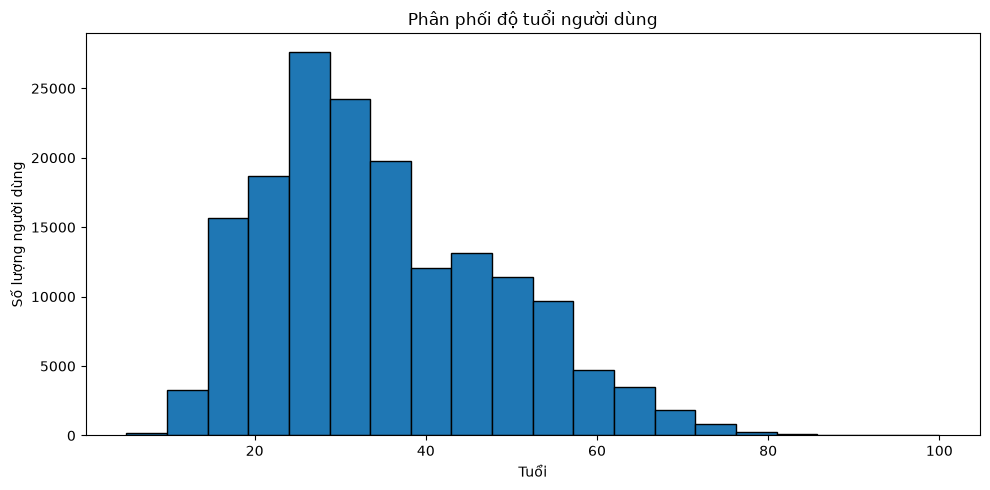

In [9]:
# Chuyển tuổi sang kiểu số để thống kê.
# Tuổi thiếu hoặc không chuyển được thành số sẽ trở thành NaN.
user_age = pd.to_numeric(users_clean["Age"],errors="coerce")
# Thống kê tuổi của người dùng.
print("\nThống kê tuổi người dùng:")
print(user_age.describe())
# Đếm số người dùng thiếu tuổi và tính tỷ lệ phần trăm.
missing_age_count = user_age.isna().sum()
missing_age_percentage = user_age.isna().mean() * 100
print("Số người dùng thiếu tuổi:", missing_age_count)
print(f"Tỷ lệ người dùng thiếu tuổi: {missing_age_percentage:.2f}%")
# Vẽ biểu đồ phân phối tuổi, bỏ qua các giá trị thiếu.
plt.figure(figsize=(10, 5))
user_age.dropna().plot(kind="hist",bins=20,edgecolor="black")
plt.title("Phân phối độ tuổi người dùng")
plt.xlabel("Tuổi")
plt.ylabel("Số lượng người dùng")
plt.tight_layout()
plt.show()


### 4.2. PHÂN TÍCH PHÂN PHỐI ĐIỂM ĐÁNH GIÁ

Phân bố hai nhóm đánh giá:


,Số lượt đánh giá,Tỷ lệ (%)
Đánh giá cao (8–10),249887,57.62
Chưa đạt mức đánh giá cao (1–7),183784,42.38


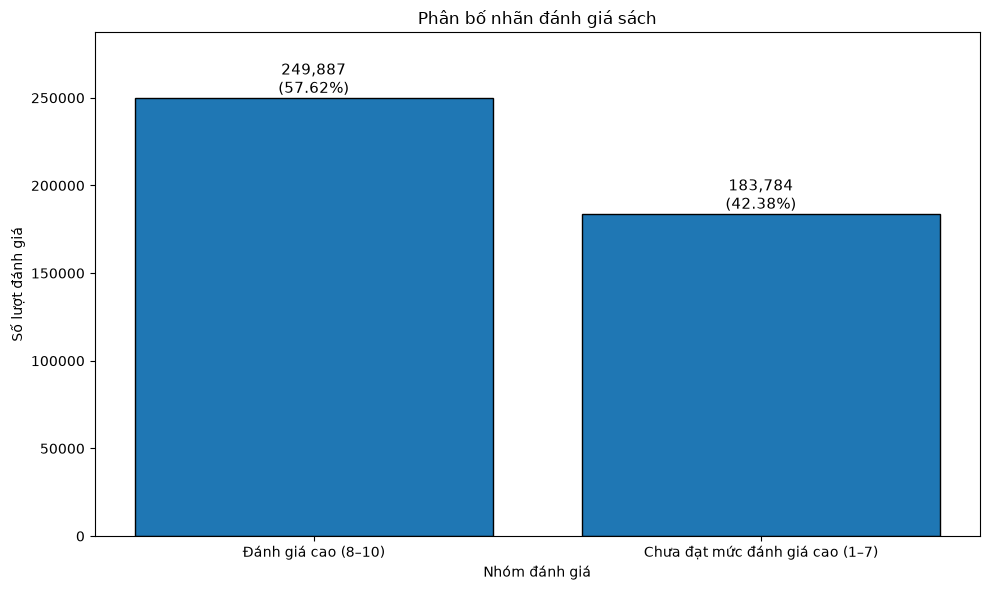

In [10]:

# Đếm số lượt đánh giá thuộc mỗi nhóm:
# liked = 1: đánh giá cao (điểm 8–10)
# liked = 0: chưa đạt mức đánh giá cao (điểm 1–7)
label_counts = (classification_data["liked"].value_counts().reindex([1, 0], fill_value=0))
# Đổi nhãn số thành tên nhóm để biểu đồ dễ đọc hơn.
label_counts.index = ["Đánh giá cao (8–10)", "Chưa đạt mức đánh giá cao (1–7)"]
# Tính tỷ lệ phần trăm của mỗi nhóm trên tổng số lượt đánh giá.
label_percentages = (label_counts / label_counts.sum() * 100)
# Tổng hợp số lượng và tỷ lệ thành bảng thống kê.
label_summary = pd.DataFrame({"Số lượt đánh giá": label_counts,"Tỷ lệ (%)": label_percentages})


# Hiển thị bảng thống kê để kiểm tra kết quả.
print("Phân bố hai nhóm đánh giá:")
display(label_summary.round(2))


# Vẽ biểu đồ cột thể hiện số lượng của hai nhóm.
plt.figure(figsize=(10, 6))
bars = plt.bar(label_counts.index,label_counts.values,edgecolor="black")


# Ghi số lượt đánh giá và tỷ lệ phần trăm lên mỗi cột.
for bar, count, percentage in zip(bars,label_counts.values,label_percentages.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11
    )
# Đặt tiêu đề, tên trục và căn chỉnh biểu đồ.
plt.title("Phân bố nhãn đánh giá sách")
plt.xlabel("Nhóm đánh giá")
plt.ylabel("Số lượt đánh giá")
plt.ylim(0, label_counts.max() * 1.15)
plt.tight_layout()
plt.show()

Số lượt đánh giá theo điểm:
Book-Rating
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Tỷ lệ phần trăm theo điểm:
Book-Rating
1      0.41
2      0.64
3      1.38
4      2.05
5     11.75
6      8.51
7     17.63
8     23.92
9     15.57
10    18.13
Name: proportion, dtype: float64


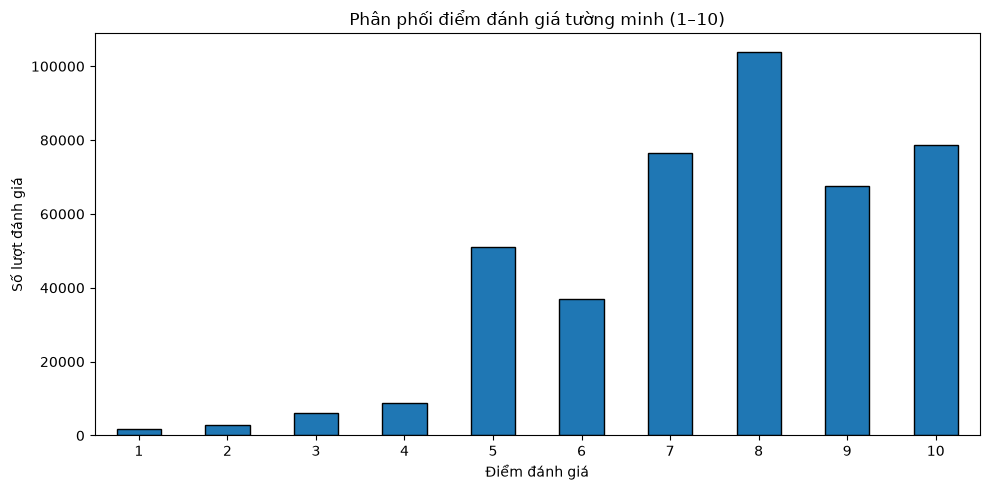

In [11]:
# Tách các lượt đánh giá có điểm tường minh từ 1 đến 10.
# Giữ nguyên ratings_clean để không làm thay đổi dữ liệu gốc đã làm sạch.
explicit_ratings = ratings_clean.loc[ratings_clean["Book-Rating"].between(1, 10)].copy()
# Đếm số lượt đánh giá theo từng điểm từ 1 đến 10.
explicit_rating_counts = (explicit_ratings["Book-Rating"].value_counts().sort_index())
# Tính tỷ lệ phần trăm của từng điểm trong nhóm đánh giá tường minh.
explicit_rating_percentages = (explicit_ratings["Book-Rating"].value_counts(normalize=True).sort_index() * 100)
# Hiển thị số lượng và tỷ lệ để so sánh các mức điểm.
print("Số lượt đánh giá theo điểm:")
print(explicit_rating_counts)
print("\nTỷ lệ phần trăm theo điểm:")
print(explicit_rating_percentages.round(2))
# Vẽ biểu đồ phân phối điểm đánh giá tường minh.
plt.figure(figsize=(10, 5))
explicit_rating_counts.plot(kind="bar", edgecolor="black")
plt.title("Phân phối điểm đánh giá tường minh (1–10)")
plt.xlabel("Điểm đánh giá")
plt.ylabel("Số lượt đánh giá")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4.3. NGƯỜI DÙNG CÓ NHIỀU LƯỢT ĐÁNH GIÁ CÓ ĐIỂM NHẤT (1–10)

Đếm các lượt có điểm 1–10; không tính điểm 0.


In [12]:
# Chỉ giữ các lượt đánh giá có điểm từ 1 đến 10.
# Book-Rating = 0 không được tính vì không phải điểm đánh giá rõ ràng.
explicit_ratings = ratings_clean.loc[ratings_clean["Book-Rating"].between(1, 10)].copy()
# Đếm số lượt đánh giá có điểm của từng người dùng.
user_rating_counts = (explicit_ratings.groupby("User-ID").size().reset_index(name="Number_of_Ratings"))
# Sắp xếp số lượt đánh giá từ cao xuống thấp và lấy 10 người dùng đầu tiên.
top_10_users = (user_rating_counts.sort_values("Number_of_Ratings", ascending=False).head(10).reset_index(drop=True))
# Đánh số thứ hạng từ 1 đến 10 để dễ theo dõi.
top_10_users.index = top_10_users.index + 1
top_10_users.index.name = "Rank"
# Hiển thị bảng kết quả.
print("TOP 10 NGƯỜI DÙNG CÓ NHIỀU LƯỢT ĐÁNH GIÁ CÓ ĐIỂM NHẤT (1–10):")
display(top_10_users)

TOP 10 NGƯỜI DÙNG CÓ NHIỀU LƯỢT ĐÁNH GIÁ CÓ ĐIỂM NHẤT (1–10):


,User-ID,Number_of_Ratings
Rank,,
1,11676,8524
2,98391,5802
3,153662,1969
4,189835,1906
5,23902,1395
6,76499,1036
7,171118,1035
8,235105,1023
9,16795,968


### 4.4. SÁCH CÓ NHIỀU LƯỢT ĐÁNH GIÁ NHẤT (0–10)

Đếm toàn bộ lượt trong bảng Ratings, bao gồm điểm 0. Số đếm này phản ánh mức độ xuất hiện trong dữ liệu, khác với số lượt có điểm 1–10 ở mục 4.3.


In [13]:
# Đếm số lượt đánh giá cho mỗi ISBN.
# Kết quả thể hiện mức độ xuất hiện của sách trong bảng Ratings.
book_rating_counts = (ratings_clean.groupby("ISBN").size().sort_values(ascending=False))
# Lấy 10 ISBN có nhiều lượt đánh giá nhất.
top_10_isbns = book_rating_counts.head(10)
# Tạo bảng thông tin sách để bổ sung tên sách cho kết quả.
# Chỉ lấy ISBN và tên sách để tránh ghép các cột không cần thiết.
book_titles = books_clean[["ISBN", "Book-Title"]].drop_duplicates(subset=["ISBN"])
# Ghép số lượt đánh giá với tên sách tương ứng.
top_10_books = (top_10_isbns.rename("Number_of_Ratings").reset_index().merge(book_titles, on="ISBN", how="left"))
# Hiển thị 10 sách có nhiều lượt đánh giá nhất.
print("\nTop 10 sách có nhiều lượt đánh giá nhất (0–10, bao gồm điểm 0):")
display(top_10_books)



Top 10 sách có nhiều lượt đánh giá nhất (0–10, bao gồm điểm 0):


,ISBN,Number_of_Ratings,Book-Title
0,0971880107,2502,Wild Animus
1,0316666343,1295,The Lovely Bones: A Novel
2,0385504209,883,The Da Vinci Code
3,0060928336,732,Divine Secrets of the Ya-Ya Sisterhood: A Novel
4,0312195516,723,The Red Tent (Bestselling Backlist)
5,044023722X,647,A Painted House
6,0679781587,639,<NA>
7,0142001740,615,The Secret Life of Bees
8,067976402X,614,Snow Falling on Cedars
9,0671027360,586,Angels &amp; Demons


### 4.5. PHÂN TÍCH MỨC ĐIỂM ĐÁNH GIÁ CỦA SÁCH

In [14]:
# Chỉ lấy những lượt đánh giá từ 1 đến 10.
# Điểm 0 không được đưa vào phép tính điểm trung bình.
explicit_rating_data = ratings_clean.loc[ratings_clean["Book-Rating"].between(1, 10)].copy()
# Tính điểm trung bình và số lượt đánh giá cho từng ISBN.
book_rating_summary = (explicit_rating_data.groupby("ISBN")["Book-Rating"].agg(["mean", "count"]).reset_index())
# Đổi tên cột để kết quả dễ đọc hơn.
book_rating_summary.columns = ["ISBN","Average_Rating","Number_of_Ratings"]
# Chỉ xét sách có ít nhất 10 lượt đánh giá để hạn chế
# việc sách có quá ít lượt đánh giá đứng đầu do ngẫu nhiên.
popular_books = book_rating_summary.loc[book_rating_summary["Number_of_Ratings"] >= 10].copy()
# Sắp xếp theo điểm trung bình giảm dần và lấy 10 sách đầu tiên.
top_10_best_books = popular_books.sort_values(by=["Average_Rating", "Number_of_Ratings"],ascending=[False, False]).head(10)
# Bổ sung tên sách để dễ diễn giải kết quả.
top_10_best_books = top_10_best_books.merge(book_titles,on="ISBN",how="left")
# Sắp xếp theo điểm trung bình giảm dần và lấy 10 sách đầu tiên.
top_10_worst_books = popular_books.sort_values(by=["Average_Rating", "Number_of_Ratings"],ascending=[True, False]).head(10)
# Bổ sung tên sách để dễ diễn giải kết quả.
top_10_worst_books = top_10_worst_books.merge(book_titles,on="ISBN",how="left")
# Hiển thị 10 sách có điểm trung bình cao nhất trong nhóm đủ lượt đánh giá.
print("\nTop 10 sách có điểm trung bình cao nhất (ít nhất 10 lượt đánh giá):")
display(top_10_best_books)
print("---------------------")
print("\nTop 10 sách có điểm trung bình thấp nhất (ít nhất 10 lượt đánh giá):")
display(top_10_worst_books)



Top 10 sách có điểm trung bình cao nhất (ít nhất 10 lượt đánh giá):


,ISBN,Average_Rating,Number_of_Ratings,Book-Title
0,1888054557,10.000000,11,Postmarked Yesteryear: 30 Rare Holiday Postcards
1,0836213319,9.923077,13,Dilbert: A Book of Postcards
2,0439425220,9.869565,23,Harry Potter and the Chamber of Secrets Postca...
3,0312992416,9.800000,10,Kiss of the Night (A Dark-Hunter Novel)
4,0394823370,9.800000,10,The Lorax
5,0394800389,9.785714,14,Fox in Socks (I Can Read It All by Myself Begi...
6,0060256656,9.750000,20,The Giving Tree
7,0312099045,9.727273,11,Route 66 Postcards: Greetings from the Mother ...
8,0618002235,9.720000,25,"The Two Towers (The Lord of the Rings, Part 2)"
9,8826703132,9.714286,21,<NA>


---------------------

Top 10 sách có điểm trung bình thấp nhất (ít nhất 10 lượt đánh giá):


,ISBN,Average_Rating,Number_of_Ratings,Book-Title
0,0971880107,4.390706,581,Wild Animus
1,3442452031,4.900000,10,Soloalbum.
2,1401088945,5.000000,10,Ground Zero and Beyond
3,0679463321,5.066667,15,Killing Time: A Novel of the Future
4,0349111863,5.076923,13,Sex and the City
5,0142000981,5.133333,15,Coal: A Human History
6,0871138190,5.166667,12,Four Blondes
7,3518368001,5.181818,11,Neue Leiden Des Jungen
8,0312288115,5.250000,20,Confessions of a Sociopathic Social Climber : ...
9,0802132952,5.285714,21,Naked Lunch


### 4.6. PHÂN TÍCH MỐI QUAN HỆ GIỮA ĐỘ TUỔI VÀ NHÃN ĐÁNH GIÁ

Thống kê độ tuổi theo nhãn:


,count,mean,median,std
Nhãn 0 (điểm 1–7),121004,35.99,34.0,12.21
Nhãn 1 (điểm 8–10),182096,36.78,35.0,12.46


Tỷ lệ nhãn trong từng nhóm tuổi (%):


liked,Nhãn 0 (điểm 1–7),Nhãn 1 (điểm 8–10)
Age_Group,,
5–18,41.49,58.51
19–30,40.26,59.74
31–45,41.54,58.46
46–60,35.96,64.04
61–100,39.12,60.88


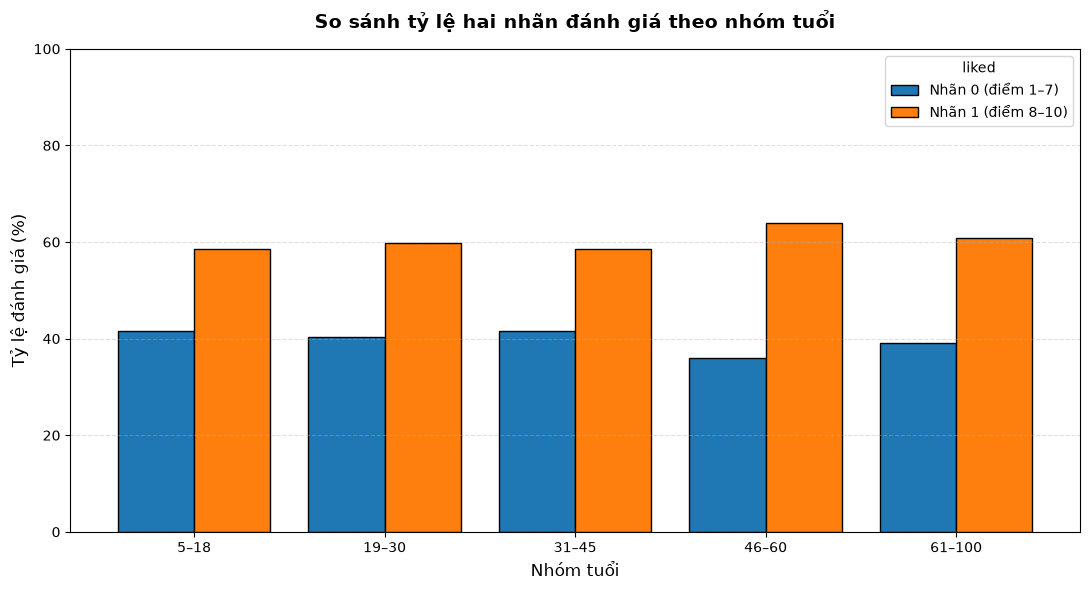

In [15]:
# Tạo bản sao để không làm thay đổi classification_data hiện có.
age_label_data = classification_data.copy()
# Chuyển Age về dạng số; giá trị không hợp lệ sẽ thành NaN.
age_label_data["Age"] = pd.to_numeric(age_label_data["Age"],errors="coerce")
# Chỉ giữ độ tuổi hợp lệ trong khoảng 5–100.
age_label_data.loc[~age_label_data["Age"].between(5, 100),"Age"] = np.nan
# Thống kê số lượng, trung bình và trung vị độ tuổi theo nhãn.
age_label_summary = (age_label_data.groupby("liked")["Age"].agg(["count", "mean", "median", "std"]))
# Đổi tên nhãn để phân biệt rõ ý nghĩa.
age_label_summary.index = ["Nhãn 0 (điểm 1–7)","Nhãn 1 (điểm 8–10)"]
print("Thống kê độ tuổi theo nhãn:")
display(age_label_summary.round(2))
# Tạo các nhóm tuổi để so sánh tỷ lệ nhãn giữa các nhóm.
age_label_data["Age_Group"] = pd.cut(age_label_data["Age"],bins=[4, 18, 30, 45, 60, 100],labels=["5–18", "19–30", "31–45", "46–60", "61–100"])
# Tính tỷ lệ nhãn 0 và 1 trong từng nhóm tuổi.
age_label_distribution = pd.crosstab(age_label_data["Age_Group"],age_label_data["liked"],normalize="index") * 100
# Đổi tên cột cho dễ đọc.
age_label_distribution = age_label_distribution.rename(columns={0: "Nhãn 0 (điểm 1–7)",1: "Nhãn 1 (điểm 8–10)"})
print("Tỷ lệ nhãn trong từng nhóm tuổi (%):")
display(age_label_distribution.round(2))
# Tạo biểu đồ cột; mỗi nhóm tuổi có hai cột tương ứng với hai nhãn(# Đặt hai cột cạnh nhau thay vì chồng lên nhau).
ax = age_label_distribution.plot(kind="bar",stacked=False,             figsize=(11, 6),width=0.8,edgecolor="black")
# Thêm tiêu đề và tên các trục.
ax.set_title("So sánh tỷ lệ hai nhãn đánh giá theo nhóm tuổi",fontsize=14,fontweight="bold",pad=15)
ax.set_xlabel("Nhóm tuổi", fontsize=12)
ax.set_ylabel("Tỷ lệ đánh giá (%)", fontsize=12)
# Giữ nguyên thứ tự và cách hiển thị tên các nhóm tuổi.
ax.tick_params(axis="x", rotation=0)
# Đặt giới hạn trục tung từ 0 đến 100% để dễ so sánh.
ax.set_ylim(0, 100)
# Hiển thị đường lưới ngang để dễ đọc giá trị.
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

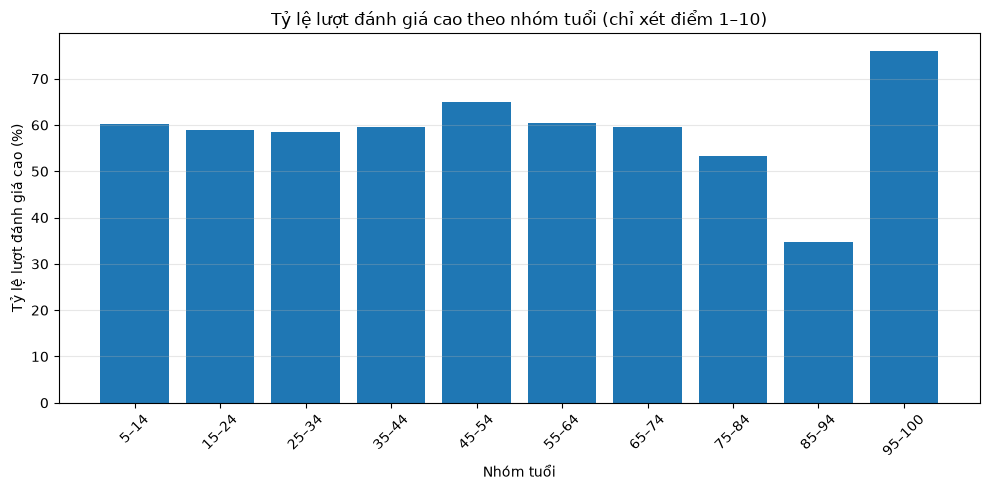

Tỷ lệ nhãn 1 theo nhóm tuổi:


,Age_Group,Number_of_Ratings,Positive_Rate
0,5–14,3875,60.28
1,15–24,42987,58.85
2,25–34,105871,58.57
3,35–44,73988,59.55
4,45–54,51458,64.93
5,55–64,18963,60.45
6,65–74,4774,59.61
7,75–84,859,53.20
8,85–94,75,34.67
9,95–100,250,76.00


Chi-square statistic: 706.6158
P-value Chi-square thông thường (chỉ tham khảo): 2.61537e-146
Diễn giải: Bảng và biểu đồ mô tả tỷ lệ lượt đánh giá cao theo nhóm tuổi trong mẫu quan sát.
Hạn chế: Một người dùng có thể đóng góp nhiều lượt đánh giá; giả định độc lập của Chi-square có thể bị vi phạm.
Vì vậy, p-value trên chỉ mang tính tham khảo, chưa đủ để khẳng định mối liên hệ trong tổng thể.


In [16]:
# Tỷ lệ lượt đánh giá cao (điểm 8–10) trong các lượt có điểm 1–10 theo nhóm tuổi
# Chỉ sử dụng các bản ghi có tuổi hợp lệ.
age_label_data = classification_data.dropna(subset=["Age", "liked"]).copy()
# Chia tuổi thành các nhóm, mỗi nhóm cách nhau 10 năm.
age_bins = [5, 15, 25, 35, 45, 55, 65, 75, 85, 95, 101]
age_labels = ["5–14", "15–24", "25–34", "35–44", "45–54","55–64", "65–74", "75–84", "85–94", "95–100"]
age_label_data["Age_Group"] = pd.cut(age_label_data["Age"],bins=age_bins,labels=age_labels,right=False,include_lowest=True)
# Tính số lượt đánh giá và tỷ lệ nhãn 1 theo nhóm tuổi.
age_summary = (age_label_data.groupby("Age_Group", observed=False).agg(Number_of_Ratings=("liked", "size"),Positive_Rate=("liked", "mean")).reset_index())
# Chuyển tỷ lệ nhãn 1 thành phần trăm.
age_summary["Positive_Rate"] *= 100
# Vẽ biểu đồ tỷ lệ nhãn 1 theo nhóm tuổi.
plt.figure(figsize=(10, 5))
plt.bar(age_summary["Age_Group"].astype(str),age_summary["Positive_Rate"])
plt.title("Tỷ lệ lượt đánh giá cao theo nhóm tuổi (chỉ xét điểm 1–10)")
plt.xlabel("Nhóm tuổi")
plt.ylabel("Tỷ lệ lượt đánh giá cao (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
# Lập bảng chéo để kiểm định mối liên hệ giữa nhóm tuổi và nhãn.
contingency_table = pd.crosstab(age_label_data["Age_Group"],age_label_data["liked"])
# Chi-square tham khảo ở cấp lượt đánh giá; các lượt của cùng người dùng có thể phụ thuộc nhau.
chi2, p_value, dof, expected = chi2_contingency(contingency_table)
print("Tỷ lệ nhãn 1 theo nhóm tuổi:")
display(age_summary.round(2))
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value Chi-square thông thường (chỉ tham khảo): {p_value:.6g}")
# Không kết luận dựa trên ngưỡng p-value khi chưa bảo đảm tính độc lập.
print("Diễn giải: Bảng và biểu đồ mô tả tỷ lệ lượt đánh giá cao theo nhóm tuổi trong mẫu quan sát.")
print("Hạn chế: Một người dùng có thể đóng góp nhiều lượt đánh giá; giả định độc lập của Chi-square có thể bị vi phạm.")
print("Vì vậy, p-value trên chỉ mang tính tham khảo, chưa đủ để khẳng định mối liên hệ trong tổng thể.")


**Phạm vi diễn giải mục 4.6:** Mỗi dòng là một lượt đánh giá có điểm 1–10, không phải một người dùng độc lập. Biểu đồ thể hiện tỷ lệ lượt đạt điểm 8–10 trong từng nhóm tuổi. Người dùng đánh giá nhiều đóng góp nhiều dòng; các lượt còn có thể cùng liên quan đến một sách. Giữ Chi-square như kết quả tham khảo, không dùng p-value này để khẳng định mối liên hệ trong tổng thể hoặc quan hệ nhân quả. Nếu cần suy luận thống kê, cần thiết kế phân tích xử lý sự phụ thuộc giữa các quan sát, chẳng hạn tổng hợp theo người dùng và xem xét ảnh hưởng của sách. Việc tổng hợp làm thay đổi đơn vị phân tích và phải được giải thích rõ.


### 4.7. PHÂN TÍCH MỐI QUAN HỆ GIỮA ĐỘ TUỔI VÀ SỐ LƯỢT ĐÁNH GIÁ SÁCH

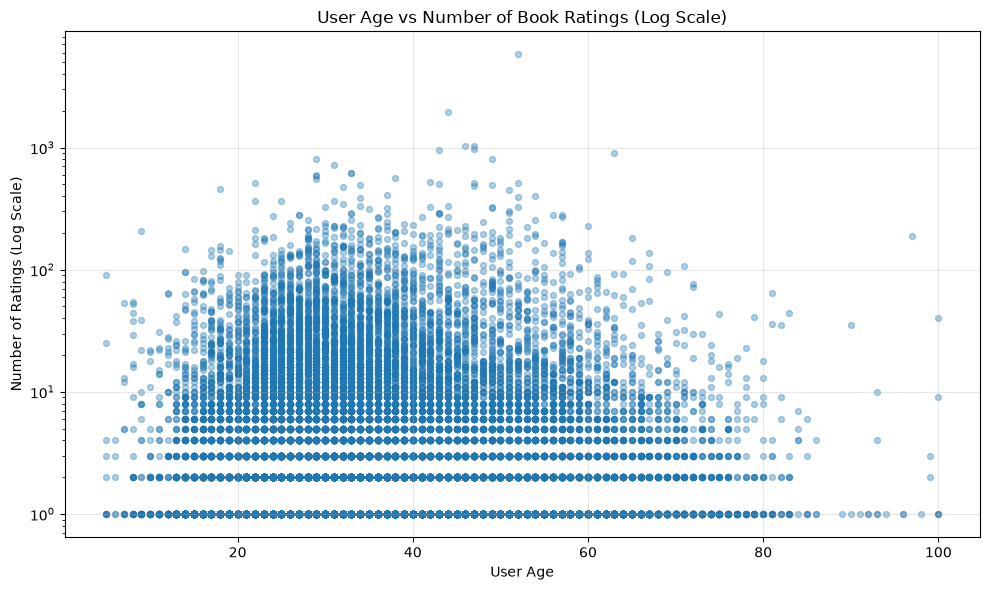

In [17]:
# Tạo biểu đồ Log Scale
# Lấy các bản ghi có tuổi hợp lệ.
age_rating_data = classification_data.dropna(subset=["Age", "User-ID"]).copy()
# Đếm số lượt đánh giá của mỗi người dùng.
user_rating_counts = (age_rating_data.groupby(["User-ID", "Age"]).size().reset_index(name="Number_of_Ratings"))
# Vẽ biểu đồ Scatter.
plt.figure(figsize=(10, 6))
plt.scatter(user_rating_counts["Age"],user_rating_counts["Number_of_Ratings"],alpha=0.35, s=18)
# Dùng thang logarit để thể hiện rõ các giá trị nhỏ và lớn.
plt.yscale("log")
plt.title("User Age vs Number of Book Ratings (Log Scale)")
plt.xlabel("User Age")
plt.ylabel("Number of Ratings (Log Scale)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

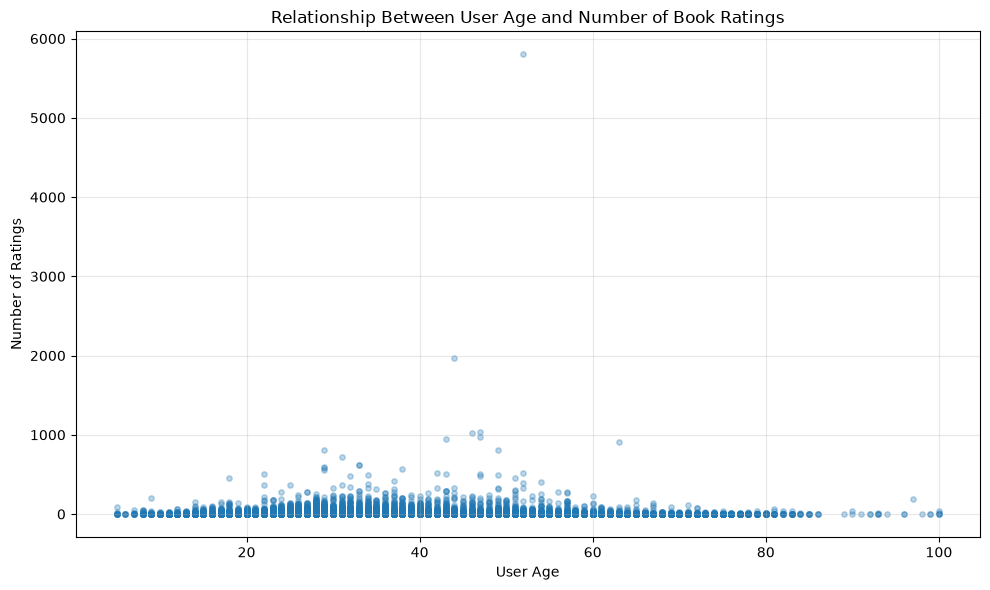

In [18]:
# Tạo biểu đồ Scatter.
plt.figure(figsize=(10, 6))
plt.scatter(user_rating_counts["Age"],user_rating_counts["Number_of_Ratings"],alpha=0.3,s=15)
# Đặt tên biểu đồ và các trục.
plt.title("Relationship Between User Age and Number of Book Ratings")
plt.xlabel("User Age")
plt.ylabel("Number of Ratings")
# Hiển thị lưới để dễ quan sát.
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4.8. MỨC ĐỘ HOẠT ĐỘNG CỦA NGƯỜI DÙNG VÀ TỶ LỆ ĐÁNH GIÁ POSITIVE 

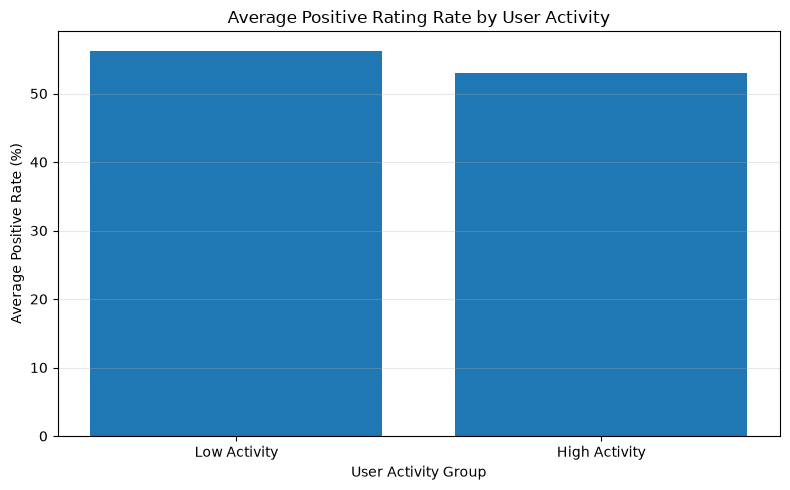

Bảng so sánh mức độ hoạt động:


,Group,Number_of_Users,Median_Ratings_Per_User,Average_Positive_Rate
0,Low Activity,45382,1.0,56.27
1,High Activity,22568,6.0,53.00


Mann–Whitney U statistic: 566384643.0000
P-value: 3.21475e-125
Chênh lệch tỷ lệ nhãn 1: -3.28 điểm phần trăm
Kết luận: Có bằng chứng thống kê cho thấy phân phối tỷ lệ nhãn 1 khác nhau giữa nhóm hoạt động thấp và cao.


In [19]:
# Tổng hợp số lượt đánh giá và tỷ lệ nhãn 1 của từng người dùng.
user_activity = (classification_data.groupby("User-ID").agg(Number_of_Ratings=("liked", "size"),Positive_Rate=("liked", "mean")).reset_index())
# Tính ngưỡng phân vị 25% và 75% của số lượt đánh giá.
q25 = user_activity["Number_of_Ratings"].quantile(0.25)
q75 = user_activity["Number_of_Ratings"].quantile(0.75)
# Chỉ giữ nhóm hoạt động thấp và nhóm hoạt động cao.
low_activity = user_activity[user_activity["Number_of_Ratings"] <= q25].copy()
high_activity = user_activity[user_activity["Number_of_Ratings"] >= q75
].copy()
# Tổng hợp số người dùng và tỷ lệ nhãn 1 trung bình trong mỗi nhóm.
activity_summary = pd.DataFrame({"Group": ["Low Activity", "High Activity"],"Number_of_Users": [len(low_activity),len(high_activity)],
    "Median_Ratings_Per_User": [
        low_activity["Number_of_Ratings"].median(),
        high_activity["Number_of_Ratings"].median()
    ],
    "Average_Positive_Rate": [
        low_activity["Positive_Rate"].mean() * 100,
        high_activity["Positive_Rate"].mean() * 100
    ]
})
# Vẽ biểu đồ so sánh tỷ lệ nhãn 1 trung bình của mỗi người dùng.
plt.figure(figsize=(8, 5))
plt.bar(activity_summary["Group"],activity_summary["Average_Positive_Rate"])
plt.title("Average Positive Rating Rate by User Activity")
plt.xlabel("User Activity Group")
plt.ylabel("Average Positive Rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
# Kiểm định Mann–Whitney U trên tỷ lệ nhãn 1 của từng người dùng.
# Mỗi người dùng chỉ đóng góp một giá trị tỷ lệ vào kiểm định.
u_statistic, p_value = mannwhitneyu(low_activity["Positive_Rate"],high_activity["Positive_Rate"],alternative="two-sided")
print("Bảng so sánh mức độ hoạt động:")
display(activity_summary.round(2))
print(f"Mann–Whitney U statistic: {u_statistic:.4f}")
print(f"P-value: {p_value:.6g}")
# So sánh tỷ lệ nhãn 1 trung bình giữa hai nhóm.
low_rate = low_activity["Positive_Rate"].mean() * 100
high_rate = high_activity["Positive_Rate"].mean() * 100
print(f"Chênh lệch tỷ lệ nhãn 1: {high_rate - low_rate:.2f} điểm phần trăm")
if p_value < 0.05:
    print("Kết luận: Có bằng chứng thống kê cho thấy phân phối tỷ lệ ""nhãn 1 khác nhau giữa nhóm hoạt động thấp và cao.")
else:
    print("Kết luận: Chưa có đủ bằng chứng thống kê về sự khác biệt ""tỷ lệ nhãn 1 giữa hai nhóm.")

### 4.9. EDA Summary

Kết quả khám phá dữ liệu (EDA) cho thấy bốn phát hiện đáng chú ý:

- **Phân phối nhãn:** Nhãn 1 (điểm đánh giá 8–10) chiếm 57,62%, cao hơn nhãn 0 (điểm đánh giá 1–7) với 42,38%. Mặc dù có sự chênh lệch giữa hai nhãn, mức độ mất cân bằng chưa quá lớn. Tuy nhiên, cần xem xét phân phối nhãn khi đánh giá hiệu quả mô hình phân loại.

- **Hành vi người dùng:** Số lượt đánh giá phân bố không đồng đều, với một số người dùng hoạt động vượt trội so với phần còn lại. Phân tích sâu hơn cho thấy nhóm người dùng có ít lượt đánh giá có tỷ lệ nhãn 1 trung bình là 56,27%, cao hơn nhóm hoạt động cao với 53,00%, chênh lệch khoảng 3,28 điểm phần trăm. Kiểm định Mann–Whitney U cho p-value = 3,21475 × 10⁻¹²⁵, cung cấp bằng chứng thống kê về sự khác biệt trong phân phối tỷ lệ nhãn 1 giữa hai nhóm. Kết quả gợi ý mức độ hoạt động có liên quan đến hành vi đánh giá, nhưng không chứng minh số lượt đánh giá nhiều khiến người dùng cho điểm thấp hơn.

- **Mức độ phổ biến của sách:** Các bảng top ở mục 4.4–4.5 mô tả hai tiêu chí khác nhau: số lượt đánh giá (bao gồm điểm 0) và điểm trung bình (chỉ tính điểm 1–10, với ít nhất 10 lượt có điểm). Việc đối chiếu các bảng này mới mang tính mô tả; chưa đủ để kết luận về mối quan hệ giữa độ phổ biến và điểm trung bình trên toàn bộ sách.

- **Vai trò của độ tuổi:** Trong mẫu quan sát, tỷ lệ lượt đánh giá cao khác nhau giữa các nhóm tuổi. Nhóm 45–54 tuổi đạt 64,93%; nhóm 85–94 tuổi đạt 34,67% nhưng chỉ có 75 lượt đánh giá. Các tỷ lệ được tính theo lượt đánh giá, nên người dùng có nhiều lượt đóng góp trọng số lớn hơn. Chi-square thông thường cho p-value = 2,61537 × 10⁻¹⁴⁶, nhưng một người dùng có thể đóng góp nhiều lượt, khiến giả định độc lập có thể bị vi phạm. Vì vậy, p-value chỉ được báo cáo để tham khảo, chưa đủ để khẳng định mối liên hệ trong tổng thể. Khoảng 40,17% người dùng thiếu tuổi sau làm sạch; đây là tỷ lệ ở cấp người dùng, khác với tỷ lệ thiếu tuổi trong tập lượt đánh giá phân loại.


**Kết luận:** EDA mô tả sự khác biệt về hành vi đánh giá trong mẫu theo người dùng và nhóm tuổi. Các bảng top sách giúp xem xét riêng số lượt đánh giá và điểm trung bình; chưa xác lập mối quan hệ giữa hai đại lượng trên toàn bộ sách. Đây là cơ sở để lựa chọn và kiểm tra các đặc trưng tiềm năng khi xây dựng mô hình phân loại. Tuy nhiên, mối liên hệ có ý nghĩa thống kê không đồng nghĩa với khả năng dự đoán tốt, vì vậy cần đánh giá vai trò thực tế của từng đặc trưng trên tập validation trước khi đánh giá cuối cùng trên test. Quá trình xây dựng mô hình cũng cần xem xét dữ liệu tuổi bị thiếu, sự khác biệt về mức độ hoạt động giữa người dùng và khả năng tổng quát hóa của mô hình. Đặc biệt, không sử dụng `Book-Rating` làm đặc trưng đầu vào vì nhãn `liked` được tạo trực tiếp từ cột này, dẫn đến rò rỉ dữ liệu (*data leakage*).

### 4.10. Target và các đặc trưng dự kiến

Đơn vị dự đoán là một lượt đánh giá của một người dùng đối với một sách. Tập phân loại chỉ gồm các lượt có `Book-Rating` từ 1–10. Bảng dưới xác định target và các đầu vào dự kiến để thử nghiệm ở phần 5; đây chưa phải kết luận đặc trưng nào dự đoán tốt nhất.

| Vai trò | Biến | Lý do chọn / ý nghĩa | Cách xử lý dự kiến |
|---|---|---|---|
| Target | `liked` | 1: điểm 8–10; 0: điểm 1–7. Ngưỡng 8 là quy ước của nhóm. | Giữ dạng nhị phân; không đưa vào X. |
| Đầu vào ban đầu | `Age` | EDA cho thấy tỷ lệ đánh giá cao khác nhau giữa các nhóm tuổi; cần kiểm tra khả năng dự đoán thực tế. | Điền median từ train; chuẩn hóa nếu thuật toán cần. |
| Đầu vào ban đầu | `Age_missing` | Phân biệt tuổi quan sát được với tuổi được điền. | Chuyển cờ boolean thành 0/1. |
| Đầu vào ban đầu | `Year-Of-Publication` | Thử kiểm tra liệu năm xuất bản có giúp phân biệt hai nhãn; EDA hiện chưa chứng minh mối liên hệ này. | Điền median từ train; chuẩn hóa nếu thuật toán cần. |
| Đầu vào ban đầu | `Year_missing` | Đánh dấu năm thiếu hoặc không hợp lệ, kể cả trường hợp không khớp sách. | Dùng cờ đã cập nhật sau merge, chuyển thành 0/1. |
| Đầu vào mở rộng | `Book-Author`, `Publisher` | Thử khai thác khác biệt giữa tác giả/nhà xuất bản; chưa có bằng chứng EDA trực tiếp về khả năng dự đoán. | Điền `Unknown`; học nhóm hiếm và bộ mã hóa trên train; xử lý được nhóm chưa gặp ở validation/test. |
| Đầu vào mở rộng | Quốc gia trích từ `Location` | Thử biểu diễn vị trí ở mức khái quát, giảm số lượng giá trị so với chuỗi vị trí đầy đủ. | Tạo biến mới bằng quy tắc tách và chuẩn hóa được kiểm tra; giá trị không xác định thành `Unknown`; mã hóa trên train. Biến này chưa được tạo ở phần EDA. |
| Đầu vào mở rộng | Số lượt đánh giá theo người dùng/sách | EDA cho thấy mức hoạt động và mức phổ biến không đồng đều; có thể cung cấp tín hiệu dự đoán. | Tạo biến mới chỉ từ train; khi tạo giá trị cho chính train, loại lượt hiện tại khỏi số đếm. Với validation/test, tra bảng thống kê từ train; ID chưa gặp gán 0. |
| Đầu vào nâng cao, tùy chọn | Điểm trung bình hoặc tỷ lệ nhãn 1 theo người dùng/sách | Thử biểu diễn xu hướng đánh giá; có nguy cơ rò rỉ vì sử dụng điểm/nhãn. | Không dùng các bảng tổng hợp toàn bộ dữ liệu ở EDA làm đầu vào. Tạo đặc trưng train bằng out-of-fold: mỗi dòng nhận thống kê từ các fold khác; validation/test chỉ dùng thống kê từ train. Nhóm chưa gặp dùng giá trị chung của train. |

**Các cột không dùng trực tiếp làm đầu vào:**

- `Book-Rating`: loại khỏi X vì `liked` được tạo trực tiếp từ điểm này, sẽ gây rò rỉ target.
- `User-ID`, `ISBN`: giữ làm khóa ghép, chia dữ liệu và tính thống kê; không coi các mã định danh là biến số liên tục.
- `Book-Title` và chuỗi `Location` đầy đủ: chưa đưa vào mô hình ban đầu vì cần bước xử lý văn bản hoặc chuẩn hóa riêng.
- `book_match`: dùng để kiểm tra chất lượng ghép; chưa chọn làm đầu vào ban đầu. `user_match` không phân biệt được các mẫu trong dữ liệu hiện tại vì tất cả đều khớp người dùng.
- Các cột URL ảnh: chưa sử dụng vì phạm vi hiện tại không xử lý ảnh.

**Nguyên tắc thực hiện ở phần 5:**

1. Chia train/validation/test trước khi học median, bộ chuẩn hóa, nhóm giá trị hiếm, bộ mã hóa hoặc các thống kê theo người dùng/sách. Chọn cách chia phù hợp với mục tiêu dự đoán cho người dùng/sách đã biết hay chưa gặp.
2. Bắt đầu bằng nhóm đầu vào ban đầu; thử bổ sung các nhóm mở rộng và so sánh trên validation. Giữ test để đánh giá cuối cùng.
3. Không xem ý nghĩa thống kê trong EDA là bằng chứng chắc chắn về khả năng dự đoán. Chọn đặc trưng dựa trên kết quả validation và khả năng áp dụng thực tế.

Phần này chỉ chốt kế hoạch đặc trưng sau EDA; chưa huấn luyện mô hình hoặc tạo các đặc trưng tổng hợp cho mô hình.


## 5. Implementing Machine Learning Algorithms

### 5.1. Mục tiêu và phương pháp thực hiện
Bài toán của chúng ta là Binary Classification — phân loại nhị phân.
- **Đơn vị dự đoán:** Một lượt đánh giá sách của một người dùng.
- **Target:** liked.
  - 1: Điểm đánh giá từ 8–10.
  - 0: Điểm đánh giá từ 1–7.
- **Dữ liệu sử dụng:** classification_data, chỉ bao gồm những lượt đánh giá có Book-Rating từ 1 đến 10.
- **Mục tiêu:** Xây dựng và so sánh các thuật toán phân loại để xác định liệu những đặc trưng sẵn có có thể dự đoán nhãn liked hay không.
- **Thuật toán sử dụng:** Logistic Regression, Decision Tree, Support Vector Machine (SVM), Neural Network (MLP).

### 5.2. Chuẩn bị dữ liệu và chia tập Train/Validation/Test
- **Training set (70%):** Dùng để huấn luyện mô hình và học các tham số tiền xử lý.
- **Validation set (15%):** Dùng để so sánh mô hình và lựa chọn đặc trưng.
- **Test set (15%):** Chỉ dùng để đánh giá cuối cùng sau khi đã lựa chọn mô hình.

In [20]:
# KIỂM TRA DỮ LIỆU TRƯỚC KHI XÂY DỰNG MÔ HÌNH
# Khai báo các cột cần thiết cho target và nhóm đặc trưng ban đầu.
target_col = "liked"
initial_features = ["Age","Age_missing","Year-Of-Publication","Year_missing"]
# Kiểm tra xem các cột cần thiết có tồn tại hay không.
required_columns = [target_col] + initial_features
missing_columns = [col for col in required_columns if col not in classification_data.columns]
if missing_columns:
    raise ValueError(f"Thiếu các cột cần thiết: {missing_columns}")
# Tạo bản sao để không làm thay đổi dữ liệu EDA ban đầu.
model_data = classification_data[required_columns].copy()
# Chuyển target thành kiểu số và loại các dòng không có target hợp lệ.
model_data[target_col] = pd.to_numeric( model_data[target_col], errors="coerce")
model_data = model_data.dropna(subset=[target_col])
# Chỉ giữ các giá trị target thuộc hai lớp 0 và 1.
model_data = model_data[model_data[target_col].isin([0, 1])].copy()
# Chuyển các đặc trưng số sang kiểu số.
# Giá trị không chuyển đổi được sẽ thành NaN để xử lý ở bước tiền xử lý.
numeric_columns = ["Age", "Year-Of-Publication"]
for col in numeric_columns: model_data[col] = pd.to_numeric(model_data[col], errors="coerce")
# Chuyển các cột đánh dấu thiếu dữ liệu về dạng 0/1.
# Nếu cờ bị thiếu, suy ra từ việc giá trị gốc có bị thiếu hay không.
model_data["Age_missing"] = (model_data["Age_missing"].fillna(model_data["Age"].isna()).astype(int))
model_data["Year_missing"] = (model_data["Year_missing"].fillna(model_data["Year-Of-Publication"].isna()).astype(int))
# Kiểm tra kích thước và tỷ lệ nhãn sau khi chuẩn bị dữ liệu.
print("Kích thước dữ liệu:", model_data.shape)
print("\nPhân phối target:")
print(model_data[target_col].value_counts())
print("\nTỷ lệ target (%):")
print((model_data[target_col].value_counts(normalize=True) * 100).round(2))
# Kiểm tra các giá trị thiếu trong nhóm đặc trưng ban đầu.
print("\nSố lượng giá trị thiếu:")
print(model_data[initial_features].isna().sum())

Kích thước dữ liệu: (433671, 5)

Phân phối target:
liked
1    249887
0    183784
Name: count, dtype: int64

Tỷ lệ target (%):
liked
1    57.62
0    42.38
Name: proportion, dtype: float64

Số lượng giá trị thiếu:
Age                    130571
Age_missing                 0
Year-Of-Publication     55636
Year_missing                0
dtype: int64


In [39]:
# CHIA TRAIN / VALIDATION / TEST
from sklearn.model_selection import train_test_split
# Tách X (đặc trưng) và y (nhãn cần dự đoán).
X = model_data[initial_features].copy()
y = model_data[target_col].astype(int).copy()
# Bước 1: Tách 15% dữ liệu làm test set.
# 85% còn lại được sử dụng để tạo train và validation.
X_train_val, X_test, y_train_val, y_test = train_test_split(X,y,test_size=0.15,random_state=56,stratify=y)
# Bước 2: Tách 15% tổng dữ liệu làm validation set.
# 15/85 xấp xỉ 17.65%, nên phần còn lại sẽ chiếm khoảng 70% tổng dữ liệu.
X_train, X_val, y_train, y_val = train_test_split(X_train_val,y_train_val,test_size=15 / 85,random_state=56,stratify=y_train_val)
# Kiểm tra kích thước từng tập.
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)
# Kiểm tra tỷ lệ nhãn trong từng tập để xác nhận stratify hoạt động.
print("\nTỷ lệ nhãn trong từng tập:")
print("Train:")
print(y_train.value_counts(normalize=True).sort_index().round(4))
print("\nValidation:")
print(y_val.value_counts(normalize=True).sort_index().round(4))
print("\nTest:")
print(y_test.value_counts(normalize=True).sort_index().round(4))

Training set: (303569, 4)
Validation set: (65051, 4)
Test set: (65051, 4)

Tỷ lệ nhãn trong từng tập:
Train:
liked
0    0.4238
1    0.5762
Name: proportion, dtype: float64

Validation:
liked
0    0.4238
1    0.5762
Name: proportion, dtype: float64

Test:
liked
0    0.4238
1    0.5762
Name: proportion, dtype: float64


### 5.3. Xây dựng các mô hình phân loại

In [22]:
# THIẾT LẬP TIỀN XỬ LÝ DỮ LIỆU
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
# Điền giá trị thiếu bằng median và chuẩn hóa các đặc trưng số.
# Khi đặt trong Pipeline, các tham số chỉ được học từ tập train.
numeric_preprocessor = Pipeline(steps=[
    # Điền Age và Year-Of-Publication còn thiếu bằng median của train.
    ("imputer", SimpleImputer(strategy="median")),
    # Đưa các đặc trưng về thang đo tương đương, hữu ích cho LR, SVM và MLP.
    ("scaler", StandardScaler())])
print("Đã thiết lập quy trình tiền xử lý.")

Đã thiết lập quy trình tiền xử lý.


In [23]:
# KHỞI TẠO CÁC MÔ HÌNH PHÂN LOẠI
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
# Khai báo các mô hình để so sánh trên cùng nhóm đặc trưng.
models = {
    # Mô hình cơ sở: hồi quy logistic cho bài toán phân loại nhị phân.
    "Logistic Regression": LogisticRegression(max_iter=1000,random_state=42),
    # Giới hạn độ sâu và số mẫu tối thiểu ở lá để hạn chế overfitting.
    "Decision Tree": DecisionTreeClassifier(max_depth=10,min_samples_leaf=50,random_state=42),
    # Linear SVM: lựa chọn phù hợp hơn RBF SVM khi dữ liệu có nhiều dòng.
    "SVM": LinearSVC(max_iter=5000,random_state=42),
    # Mạng nơ-ron MLP với hai lớp ẩn.
    # Early stopping giúp dừng khi hiệu quả trên phần validation nội bộ
    # không còn cải thiện.
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(32, 16),activation="relu",solver="adam",max_iter=30,early_stopping=True,n_iter_no_change=5,random_state=42)}
print("Các mô hình đã được khởi tạo:")
for model_name in models:
    print("-", model_name)

Các mô hình đã được khởi tạo:
- Logistic Regression
- Decision Tree
- SVM
- Neural Network (MLP)


In [24]:
# HUẤN LUYỆN VÀ ĐÁNH GIÁ TRÊN VALIDATION SET
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score)
# Danh sách lưu kết quả đánh giá của từng mô hình.
results = []
# Lưu các pipeline đã huấn luyện để sử dụng lại ở bước sau.
trained_models = {}
# Huấn luyện và đánh giá lần lượt từng thuật toán.
for model_name, model in models.items():
    print(f"\nĐang huấn luyện: {model_name}...")
    # Tạo pipeline riêng cho từng mô hình.
    # clone bảo đảm mỗi mô hình có bộ tiền xử lý riêng.
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(numeric_preprocessor)),
        ("model", model)])
    # Chỉ học các tham số tiền xử lý và huấn luyện trên tập train.
    pipeline.fit(X_train, y_train)
    # Dự đoán nhãn trên validation set.
    y_val_pred = pipeline.predict(X_val)
    # Lấy điểm dùng để tính ROC-AUC.
    # Ưu tiên xác suất dự đoán; nếu mô hình không hỗ trợ
    # predict_proba thì sử dụng decision_function.
    if hasattr(pipeline, "predict_proba"): y_val_score = pipeline.predict_proba(X_val)[:, 1]
    else: y_val_score = pipeline.decision_function(X_val)
    # Tính các chỉ số đánh giá.
    accuracy = accuracy_score(y_val, y_val_pred)
    precision = precision_score(y_val,y_val_pred,zero_division=0)
    recall = recall_score(y_val,y_val_pred,zero_division=0)
    f1 = f1_score(y_val,y_val_pred,zero_division=0)
    roc_auc = roc_auc_score(y_val, y_val_score)
    # Lưu kết quả để so sánh các mô hình.
    results.append({"Model": model_name,"Accuracy": accuracy,"Precision": precision,"Recall": recall,"F1-score": f1,"ROC-AUC": roc_auc})
    # Lưu pipeline đã huấn luyện.
    trained_models[model_name] = pipeline
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")
    print(f"ROC-AUC  : {roc_auc:.4f}")
# Chuyển kết quả thành DataFrame để dễ đọc và so sánh.
results_df = pd.DataFrame(results)
# Sắp xếp theo F1-score giảm dần để xem mô hình nào có kết quả tốt hơn
# theo chỉ số cân bằng giữa Precision và Recall.
results_df = results_df.sort_values(by="F1-score",ascending=False).reset_index(drop=True)
print("\nBẢNG SO SÁNH CÁC MÔ HÌNH TRÊN VALIDATION SET")
display(results_df.round(4))


Đang huấn luyện: Logistic Regression...
Accuracy : 0.5776
Precision: 0.5799
Recall   : 0.9688
F1-score : 0.7255
ROC-AUC  : 0.5494

Đang huấn luyện: Decision Tree...
Accuracy : 0.5778
Precision: 0.5834
Recall   : 0.9347
F1-score : 0.7184
ROC-AUC  : 0.5649

Đang huấn luyện: SVM...
Accuracy : 0.5776
Precision: 0.5799
Recall   : 0.9688
F1-score : 0.7255
ROC-AUC  : 0.5494

Đang huấn luyện: Neural Network (MLP)...
Accuracy : 0.5776
Precision: 0.5799
Recall   : 0.9688
F1-score : 0.7255
ROC-AUC  : 0.5528

BẢNG SO SÁNH CÁC MÔ HÌNH TRÊN VALIDATION SET


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.5776,0.5799,0.9688,0.7255,0.5494
1,SVM,0.5776,0.5799,0.9688,0.7255,0.5494
2,Neural Network (MLP),0.5776,0.5799,0.9688,0.7255,0.5528
3,Decision Tree,0.5778,0.5834,0.9347,0.7184,0.5649


In [40]:
# KIỂM TRA: SO SÁNH VỚI BASELINE CHỈ DỰ ĐOÁN NHÃN PHỔ BIẾN NHẤT
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
# Khởi tạo mô hình cơ sở: luôn dự đoán lớp phổ biến nhất trong train.
# Mô hình này không học mối quan hệ giữa đặc trưng và target.
baseline_model = DummyClassifier(strategy="most_frequent")
# Huấn luyện baseline trên tập train.
baseline_model.fit(X_train, y_train)
# Dự đoán trên cùng validation set để so sánh công bằng.
y_baseline_pred = baseline_model.predict(X_val)
# Tính các chỉ số đánh giá baseline.
baseline_accuracy = accuracy_score(y_val, y_baseline_pred)
baseline_f1 = f1_score(y_val, y_baseline_pred, zero_division=0)
print("BASELINE - MOST FREQUENT")
print(f"Accuracy: {baseline_accuracy:.4f}")
print(f"F1-score: {baseline_f1:.4f}")
# So sánh baseline với các mô hình đã huấn luyện.
print("\nSO SÁNH VỚI CÁC MÔ HÌNH")
comparison_df = results_df[["Model", "Accuracy", "F1-score", "ROC-AUC"]].copy()
display(comparison_df.round(4))

BASELINE - MOST FREQUENT
Accuracy: 0.5762
F1-score: 0.7311

SO SÁNH VỚI CÁC MÔ HÌNH


,Model,Accuracy,F1-score,ROC-AUC
0,Logistic Regression,0.5776,0.7255,0.5494
1,SVM,0.5776,0.7255,0.5494
2,Neural Network (MLP),0.5776,0.7255,0.5528
3,Decision Tree,0.5778,0.7184,0.5649


In [41]:
# KIỂM TRA: MA TRẬN NHẦM LẪN CỦA TỪNG MÔ HÌNH
from sklearn.metrics import confusion_matrix, classification_report
# Hiển thị kết quả cho từng mô hình trên validation set.
for model_name, pipeline in trained_models.items():
    # Dự đoán nhãn trên validation.
    y_pred = pipeline.predict(X_val)
    # Ma trận nhầm lẫn theo thứ tự nhãn 0, 1.
    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])
    print(f"\n{'=' * 55}")
    print(f"Mô hình: {model_name}")
    print("Ma trận nhầm lẫn:")
    print(cm)
    # Báo cáo Precision, Recall và F1-score của từng lớp.
    print("\nClassification report:")
    print(classification_report(
            y_val,
            y_pred,
            labels=[0, 1],
            target_names=["Nhãn 0 (điểm 1-7)", "Nhãn 1 (điểm 8-10)"],
            zero_division=0
        ))


Mô hình: Logistic Regression
Ma trận nhầm lẫn:
[[ 1220 26348]
 [ 1275 36208]]

Classification report:
                    precision    recall  f1-score   support

 Nhãn 0 (điểm 1-7)       0.49      0.04      0.08     27568
Nhãn 1 (điểm 8-10)       0.58      0.97      0.72     37483

          accuracy                           0.58     65051
         macro avg       0.53      0.51      0.40     65051
      weighted avg       0.54      0.58      0.45     65051


Mô hình: Decision Tree
Ma trận nhầm lẫn:
[[ 2583 24985]
 [ 2559 34924]]

Classification report:
                    precision    recall  f1-score   support

 Nhãn 0 (điểm 1-7)       0.50      0.09      0.16     27568
Nhãn 1 (điểm 8-10)       0.58      0.93      0.72     37483

          accuracy                           0.58     65051
         macro avg       0.54      0.51      0.44     65051
      weighted avg       0.55      0.58      0.48     65051


Mô hình: SVM
Ma trận nhầm lẫn:
[[ 1220 26348]
 [ 1275 36208]]

Classifica

**Đánh giá Confusion Matrix và Classification Report**
Kết quả đánh giá Neural Network (MLP) cho thấy mô hình có xu hướng dự đoán Nhãn 1 (điểm 8–10). Recall của Nhãn 1 đạt khoảng 0,97, trong khi Recall của Nhãn 0 (điểm 1–7) chỉ khoảng 0,04. Điều này cho thấy mô hình nhận diện tốt các trường hợp thuộc Nhãn 1 nhưng bỏ sót phần lớn các trường hợp thuộc Nhãn 0. Macro F1-score đạt 0,40, phản ánh khả năng phân loại giữa hai nhãn còn hạn chế. Do đó, cần thử nghiệm điều chỉnh ngưỡng phân loại, sử dụng trọng số lớp và cải thiện đặc trưng trước khi lựa chọn mô hình cuối cùng.

### 5.5. Mở rộng đặc trưng và đánh giá cuối cùng
Sau khi hoàn thành thực nghiệm ban đầu, chúng ta sẽ triển khai tiếp theo thứ tự:
-  **Thử nghiệm đặc trưng mở rộng:** Bổ sung Book-Author, Publisher và quốc gia trích từ Location; sử dụng bộ mã hóa phù hợp và chỉ học cách xử lý trên tập train.
- **So sánh các nhóm đặc trưng:** Đánh giá liệu các đặc trưng mở rộng có thực sự cải thiện kết quả trên validation set hay không.
- **Lựa chọn mô hình:** Chọn mô hình và nhóm đặc trưng dựa trên kết quả validation cùng mục tiêu dự đoán.
- **Đánh giá trên Test set:** Chỉ thực hiện sau khi đã chốt phương án, nhằm ước lượng hiệu quả trên dữ liệu chưa dùng để lựa chọn mô hình.

### 5.5.1. Thử nghiệm bổ sung Book-Author và Publisher

In [43]:

# CHUẨN BỊ ĐẶC TRƯNG MỞ RỘNG
# Xác định các đặc trưng phân loại cần bổ sung.
categorical_features = ["Book-Author", "Publisher"]
# Kiểm tra các cột có tồn tại trong dữ liệu hay không.
missing_columns = [
    col for col in categorical_features
    if col not in classification_data.columns]
if missing_columns:
    raise ValueError(f"Thiếu các cột: {missing_columns}")
# Tạo bộ dữ liệu gồm đặc trưng ban đầu và đặc trưng mở rộng.
# Giữ nguyên index để ghép đúng với các tập train và validation.
X_extended = classification_data.loc[
    model_data.index,
    initial_features + categorical_features].copy()
# Chuẩn hóa dữ liệu phân loại để tránh lỗi khi xử lý pd.NA.
for col in categorical_features:
    # Chuyển dữ liệu về kiểu object để xử lý thống nhất.
    X_extended[col] = X_extended[col].astype(object)
    # Thay các giá trị thiếu bằng np.nan.
    X_extended[col] = X_extended[col].where(
        pd.notna(X_extended[col]),
        np.nan)
    # Loại bỏ khoảng trắng ở đầu/cuối chuỗi.
    # Chuỗi rỗng sau khi làm sạch được xem là giá trị thiếu.
    X_extended[col] = X_extended[col].map(
        lambda value: value.strip()
        if isinstance(value, str)
        else value)
    X_extended[col] = X_extended[col].replace(
        r"^\s*$",
        np.nan,
        regex=True)
# Lấy đúng các dòng thuộc từng tập đã chia trước đó.
X_train_extended = X_extended.loc[X_train.index].copy()
X_val_extended = X_extended.loc[X_val.index].copy()
# Kiểm tra kết quả.
print("Train:", X_train_extended.shape)
print("Validation:", X_val_extended.shape)
print("\nSố giá trị thiếu trong train:")
print(X_train_extended[categorical_features].isna().sum())
print("\nSố giá trị thiếu trong validation:")
print(X_val_extended[categorical_features].isna().sum())
print("\nĐã chuẩn hóa dữ liệu phân loại.")

Train: (303569, 6)
Validation: (65051, 6)

Số giá trị thiếu trong train:
Book-Author    34791
Publisher      34791
dtype: int64

Số giá trị thiếu trong validation:
Book-Author    7469
Publisher      7469
dtype: int64

Đã chuẩn hóa dữ liệu phân loại.


In [63]:
# ĐÁNH GIÁ MÔ HÌNH VỚI ĐẶC TRƯNG MỞ RỘNG
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score)
# Danh sách lưu kết quả của các mô hình mở rộng.
extended_results = []
# Lưu các pipeline đã huấn luyện.
extended_trained_models = {}
# Lặp qua bốn thuật toán đã xác định ở phần 5.3.
for model_name, model in models.items():
    print(f"\nĐang huấn luyện: {model_name} với đặc trưng mở rộng...")
    # Tạo pipeline tiền xử lý và mô hình.
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(extended_preprocessor)),
        ("model", clone(model))])
    # Huấn luyện chỉ bằng tập train.
    pipeline.fit(X_train_extended, y_train)
    # Dự đoán trên validation.
    y_pred = pipeline.predict(X_val_extended)
    # Lấy điểm dự đoán để tính ROC-AUC.
    if hasattr(pipeline, "predict_proba"):y_score = pipeline.predict_proba(X_val_extended)[:, 1]
    else:y_score = pipeline.decision_function(X_val_extended)
    # Tính các chỉ số đánh giá.
    extended_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0),
        "F1-score": f1_score(
            y_val, y_pred, zero_division=0),
        "Macro-F1": f1_score(
            y_val, y_pred, average="macro", zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_score)})
    # Lưu pipeline đã huấn luyện.
    extended_trained_models[model_name] = pipeline
# Chuyển kết quả thành bảng.
extended_results_df = pd.DataFrame(extended_results)
# Sắp xếp theo Macro-F1 để ưu tiên đánh giá cân bằng hai lớp.
extended_results_df = extended_results_df.sort_values(
    by="Macro-F1",
    ascending=False
).reset_index(drop=True)
print("\nKẾT QUẢ VỚI ĐẶC TRƯNG MỞ RỘNG")
display(extended_results_df.round(4))


Đang huấn luyện: Logistic Regression với đặc trưng mở rộng...

Đang huấn luyện: Decision Tree với đặc trưng mở rộng...

Đang huấn luyện: SVM với đặc trưng mở rộng...

Đang huấn luyện: Neural Network (MLP) với đặc trưng mở rộng...

KẾT QUẢ VỚI ĐẶC TRƯNG MỞ RỘNG


,Model,Accuracy,Precision,Recall,F1-score,Macro-F1,ROC-AUC
0,Neural Network (MLP),0.5893,0.5989,0.8696,0.7093,0.5050,0.5950
1,Logistic Regression,0.5889,0.5981,0.8737,0.7101,0.5019,0.5846
2,SVM,0.5887,0.5978,0.8749,0.7103,0.5009,0.5851
3,Decision Tree,0.5816,0.5844,0.9478,0.7230,0.4340,0.5658


In [64]:
# SO SÁNH NHÓM ĐẶC TRƯNG BAN ĐẦU VÀ MỞ RỘNG
# Chọn các chỉ số quan trọng từ kết quả ban đầu.
initial_comparison = results_df[["Model", "Accuracy", "F1-score", "ROC-AUC"]].copy()
initial_comparison["Feature_Set"] = "Initial"
# Chọn các chỉ số tương ứng từ kết quả mở rộng.
extended_comparison = extended_results_df[["Model", "Accuracy", "F1-score", "ROC-AUC"]].copy()
extended_comparison["Feature_Set"] = "Extended"
# Ghép hai bảng để so sánh.
feature_comparison = pd.concat(
    [initial_comparison, extended_comparison],
    ignore_index=True)
# Hiển thị bảng kết quả.
display(feature_comparison.sort_values(["Model", "Feature_Set"]).round(4))

,Model,Accuracy,F1-score,ROC-AUC,Feature_Set
7,Decision Tree,0.5816,0.7230,0.5658,Extended
3,Decision Tree,0.5778,0.7184,0.5649,Initial
5,Logistic Regression,0.5889,0.7101,0.5846,Extended
0,Logistic Regression,0.5776,0.7255,0.5494,Initial
4,Neural Network (MLP),0.5893,0.7093,0.5950,Extended
2,Neural Network (MLP),0.5776,0.7255,0.5528,Initial
6,SVM,0.5887,0.7103,0.5851,Extended
1,SVM,0.5776,0.7255,0.5494,Initial


**Kết luận:** Kết quả này cho thấy **Feature Set mở rộng (Extended)** cải thiện **Accuracy và ROC-AUC** của cả 4 mô hình, nhưng F1-score lại giảm.
- **Accuracy:** SVM với Extended đạt cao nhất, ở mức 59,00%. Tuy nhiên, mức tăng so với mô hình cơ sở vẫn khá nhỏ.
- **F1-score:** Decision Tree với Extended đạt 0,7250, cao nhất trong nhóm Extended. Dù vậy, không nên chỉ dựa vào F1-score để kết luận mô hình tốt nhất vì chỉ số này có thể bị chi phối bởi khả năng dự đoán nhãn 1.
- **ROC-AUC:** MLP với Extended đạt 0,5935, cao nhất trong các mô hình. Kết quả này cho thấy khả năng phân biệt hai nhãn được cải thiện, nhưng vẫn còn khá hạn chế.
- **Tác động của đặc trưng mở rộng:** Việc bổ sung Book-Author và Publisher giúp tăng Accuracy và ROC-AUC ở cả bốn mô hình. Tuy nhiên, F1-score giảm ở Logistic Regression, MLP và SVM, cho thấy việc bổ sung đặc trưng không cải thiện đồng đều mọi khía cạnh của hiệu suất.

### 5.5.2. Thử nghiệm bổ sung Location

In [65]:
# TRÍCH XUẤT QUỐC GIA TỪ LOCATION
# Tạo bản sao để không thay đổi classification_data gốc.
location_data = classification_data.copy()
# Chuyển Location sang kiểu chuỗi có hỗ trợ giá trị thiếu.
# Chuẩn hóa khoảng trắng và chuyển các giá trị rỗng thành NaN.
location_data["Location"] = (location_data["Location"].astype("string").str.strip().replace("", pd.NA))
# Lấy phần cuối cùng sau dấu phẩy làm quốc gia dự kiến.
location_data["Country"] = (location_data["Location"].str.split(",").str[-1].str.strip().str.lower())
# Đưa các giá trị thiếu hoặc rỗng về Unknown.
location_data["Country"] = (location_data["Country"].replace("", pd.NA).fillna("Unknown"))
# Kiểm tra một số dòng sau khi trích xuất.
display(location_data[["Location", "Country"]].head(10))
# Xem các quốc gia xuất hiện nhiều nhất.
display(location_data["Country"].value_counts().head(20))
# Kiểm tra tỷ lệ giá trị Unknown.
unknown_rate = (location_data["Country"].eq("Unknown").mean() * 100)
print(f"Tỷ lệ Country = Unknown: {unknown_rate:.2f}%")

,Location,Country
1,"seattle, washington, usa",usa
3,"rijeka, n/a, croatia",croatia
4,"rijeka, n/a, croatia",croatia
6,"salzburg, salzburg, austria",austria
7,"sydney, new south wales, australia",australia
8,"torrance, california, usa",usa
9,"berlin, berlin, germany",germany
16,"iowa city, iowa, usa",usa
19,"iowa city, iowa, usa",usa
20,"iowa city, iowa, usa",usa


Country
usa               269542
canada             39831
united kingdom     22054
germany            16822
spain              12850
Unknown            12013
australia           9878
n/a                 8537
france              6205
italy               5480
portugal            5433
netherlands         3035
switzerland         2704
malaysia            2650
new zealand         2559
austria             1635
singapore            865
brazil               788
finland              710
sweden               659
Name: count, dtype: int64

Tỷ lệ Country = Unknown: 2.77%


In [66]:
# TẠO SỐ LƯỢT ĐÁNH GIÁ THEO NGƯỜI DÙNG VÀ SÁCH
# Lấy các đặc trưng ban đầu và đặc trưng phân loại.
categorical_features_new = ["Book-Author","Publisher","Country"]
# Danh sách các đặc trưng số ban đầu.
numeric_features_new = initial_features.copy()
# Lấy dữ liệu đầu vào từ classification_data.
# Giữ nguyên index để khớp với các tập train, validation và test.
X_fe = classification_data.loc[model_data.index,initial_features + ["Book-Author", "Publisher"]].copy()
# Bổ sung quốc gia đã trích xuất ở Bước 1.
X_fe["Country"] = location_data.loc[model_data.index, "Country"]
# Tách dữ liệu train theo index đã được chia từ trước.
train_rows = classification_data.loc[X_train.index, ["User-ID", "ISBN"]].copy()
# Tính số lượt xuất hiện của mỗi người dùng trong tập train.
train_user_counts = train_rows["User-ID"].value_counts()
# Tính số lượt xuất hiện của mỗi cuốn sách trong tập train.
train_book_counts = train_rows["ISBN"].value_counts()
# Tạo các tập đặc trưng riêng, không thay đổi X_train/X_val/X_test gốc.
X_train_fe = X_fe.loc[X_train.index].copy()
X_val_fe = X_fe.loc[X_val.index].copy()
X_test_fe = X_fe.loc[X_test.index].copy()

# TẠO ĐẶC TRƯNG CHO TRAIN
# Tra số lượt đánh giá của mỗi người dùng trong train.
# Trừ 1 để loại lượt đánh giá hiện tại khỏi số đếm của dòng đó.
X_train_fe["User_Rating_Count"] = (train_rows["User-ID"].map(train_user_counts).sub(1).clip(lower=0).to_numpy())
# Tương tự, loại lượt đánh giá hiện tại khỏi số đếm của sách.
X_train_fe["Book_Rating_Count"] = (train_rows["ISBN"].map(train_book_counts).sub(1).clip(lower=0).to_numpy())

# TẠO ĐẶC TRƯNG CHO VALIDATION VÀ TEST
# Validation/test chỉ sử dụng thống kê đã tính từ train.
# Người dùng hoặc sách chưa xuất hiện trong train được gán 0.
for X_part in [X_val_fe, X_test_fe]:
    # Lấy User-ID và ISBN tương ứng với các dòng cần dự đoán.
    ids = classification_data.loc[X_part.index, ["User-ID", "ISBN"]]
    # Tra số lượt đánh giá của người dùng từ train.
    X_part["User_Rating_Count"] = (ids["User-ID"].map(train_user_counts).fillna(0).to_numpy())
    # Tra số lượt đánh giá của sách từ train.
    X_part["Book_Rating_Count"] = (ids["ISBN"].map(train_book_counts).fillna(0).to_numpy())
# Thêm hai đặc trưng đếm vào danh sách đặc trưng số.
numeric_features_new += ["User_Rating_Count","Book_Rating_Count"]
# Chuẩn hóa các đặc trưng phân loại:
# - Giá trị thiếu được chuyển thành Unknown.
# - Loại bỏ khoảng trắng thừa.
# - Chuỗi rỗng cũng được chuyển thành Unknown.
for X_part in [X_train_fe, X_val_fe, X_test_fe]:
    for col in categorical_features_new:
        X_part[col] = (X_part[col].astype("object").where(X_part[col].notna(), "Unknown").map(lambda value: str(value).strip()).replace("", "Unknown"))
# Kiểm tra số lượng dòng và cột sau khi tạo đặc trưng.
print("X_train_fe:", X_train_fe.shape)
print("X_val_fe:  ", X_val_fe.shape)
print("X_test_fe: ", X_test_fe.shape)
# Xem thử dữ liệu train sau khi tạo đặc trưng.
display(X_train_fe.head())

X_train_fe: (303569, 9)
X_val_fe:   (65051, 9)
X_test_fe:  (65051, 9)


,Age,Age_missing,Year-Of-Publication,Year_missing,Book-Author,Publisher,Country,User_Rating_Count,Book_Rating_Count
445534,39.0,False,2002,False,Christina Baldwin,New World Library,usa,49,2
182201,38.0,False,1999,False,Melody Ross,Chatterbox Inc,usa,64,0
51849,<NA>,True,2003,False,LISA GARDNER,Bantam,n/a,5915,27
410749,52.0,False,2001,False,Alice Duncan,Kensington Publishing Corporation,usa,4068,1
877435,<NA>,True,2002,False,Bret Mathew Funk,Tyrannosaurus Press,usa,0,3


In [67]:
# KIỂM TRA PHÂN PHỐI CÁC ĐẶC TRƯNG ĐẾM
# Xem thống kê mô tả số lượt đánh giá theo người dùng.
print("Thống kê User_Rating_Count:")
display(X_train_fe["User_Rating_Count"].describe())
# Xem thống kê mô tả số lượt đánh giá theo sách.
print("Thống kê Book_Rating_Count:")
display(X_train_fe["Book_Rating_Count"].describe())
# Kiểm tra số lượng giá trị bằng 0.
print("Số dòng User_Rating_Count = 0:",(X_train_fe["User_Rating_Count"] == 0).sum())
print("Số dòng Book_Rating_Count = 0:",(X_train_fe["Book_Rating_Count"] == 0).sum())

Thống kê User_Rating_Count:


count    303569.000000
mean        244.442357
std         938.264201
min           0.000000
25%           3.000000
50%          20.000000
75%          79.000000
max        5915.000000
Name: User_Rating_Count, dtype: float64

Thống kê Book_Rating_Count:


count    303569.000000
mean         14.956771
std          40.039029
min           0.000000
25%           0.000000
50%           2.000000
75%          11.000000
max         488.000000
Name: Book_Rating_Count, dtype: float64

Số dòng User_Rating_Count = 0: 37020
Số dòng Book_Rating_Count = 0: 104030


In [68]:
# XÂY DỰNG PIPELINE CHO BỘ ĐẶC TRƯNG MỚI
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,recall_score,f1_score,classification_report)
# Tiền xử lý các đặc trưng số:
# - Điền giá trị thiếu bằng median.
# - Chuẩn hóa thang đo.
numeric_preprocessor_new = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])
# Tiền xử lý các đặc trưng phân loại:
# - Điền giá trị thiếu bằng Unknown.
# - One-hot encoding.
# - Gộp các giá trị ít xuất hiện theo min_frequency.
categorical_preprocessor_new = Pipeline(steps=[
    ("imputer",SimpleImputer(
            strategy="constant",
            fill_value="Unknown")),
    ("onehot",OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=100))])
# Kết hợp hai quy trình tiền xử lý.
preprocessor_new = ColumnTransformer(
    transformers=[
        ("numeric",numeric_preprocessor_new,numeric_features_new),
        ("categorical",categorical_preprocessor_new,categorical_features_new)])
# Tạo Logistic Regression với đặc trưng mới.
lr_feature_engineered = Pipeline(steps=[
    ("preprocessor", preprocessor_new),
    ("model",LogisticRegression(max_iter=1000,random_state=42))])
# Huấn luyện chỉ bằng tập train.
lr_feature_engineered.fit(X_train_fe, y_train)
# Dự đoán trên tập validation.
y_val_pred_fe = lr_feature_engineered.predict(X_val_fe)
# In các chỉ số đánh giá.
print("=== LOGISTIC REGRESSION - FEATURE ENGINEERING ===")
print(f"Accuracy: {accuracy_score(y_val, y_val_pred_fe):.4f}")
print("Recall Nhãn 0:",f"{recall_score(y_val, y_val_pred_fe, pos_label=0):.4f}")
print("Recall Nhãn 1:",f"{recall_score(y_val, y_val_pred_fe, pos_label=1):.4f}")
print("Macro F1:",f"{f1_score(y_val, y_val_pred_fe, average='macro'):.4f}")
# Xem chi tiết kết quả theo từng nhãn.
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_val,y_val_pred_fe,
        labels=[0, 1],
        target_names=["Nhãn 0 (điểm 1–7)","Nhãn 1 (điểm 8–10)"],
        zero_division=0))

=== LOGISTIC REGRESSION - FEATURE ENGINEERING ===
Accuracy: 0.5938
Recall Nhãn 0: 0.2610
Recall Nhãn 1: 0.8386
Macro F1: 0.5283

=== CLASSIFICATION REPORT ===
                    precision    recall  f1-score   support

 Nhãn 0 (điểm 1–7)       0.54      0.26      0.35     27568
Nhãn 1 (điểm 8–10)       0.61      0.84      0.70     37483

          accuracy                           0.59     65051
         macro avg       0.57      0.55      0.53     65051
      weighted avg       0.58      0.59      0.56     65051



**Nhận xét:**
- Accuracy tăng nhẹ: Từ 58,93% lên 59,38%.
- Recall Nhãn 0 cải thiện: Từ 20,82% lên 26,10%. Mô hình nhận diện được nhiều trường hợp thuộc Nhãn 0 hơn trước, nhưng vẫn bỏ sót phần lớn nhóm này.
- Recall Nhãn 1 giảm nhẹ: Mô hình không còn nghiêng về Nhãn 1 nhiều như trước, mặc dù vẫn nhận diện tốt Nhãn 1 hơn Nhãn 0.
- Macro F1 tăng: Từ 0.5050 lên 0.5283, cho thấy hiệu quả cân bằng giữa hai nhãn đã cải thiện.

### 5.5.3. Thử nghiệm bổ sung số lượt đánh giá theo người dùng/sách

In [ ]:

# Khai báo các đặc trưng cần thử nghiệm
# Hai đặc trưng số lượt đánh giá cần kiểm tra tác động.
count_features = ["User_Rating_Count","Book_Rating_Count"]
# Các đặc trưng số khác, không bao gồm hai biến đếm.
numeric_features_without_count = [col for col in numeric_features_newif col not in count_features]
# Giữ nguyên các đặc trưng phân loại trong cả hai thí nghiệm.
categorical_features = categorical_features_new
# Tập đặc trưng có bổ sung số lượt đánh giá.
X_train_count = X_train_fe.copy()
X_val_count = X_val_fe.copy()
# Tập đặc trưng không có số lượt đánh giá.
# Chỉ loại hai cột đếm, không thay đổi các cột còn lại.
X_train_no_count = X_train_fe.drop(columns=count_features).copy()
X_val_no_count = X_val_fe.drop(columns=count_features).copy()
# Kiểm tra sự khác biệt giữa hai bộ đặc trưng.
print("Số đặc trưng không có biến đếm:", X_train_no_count.shape[1])
print("Số đặc trưng có biến đếm:", X_train_count.shape[1])
# Xác nhận hai bộ dữ liệu chỉ khác nhau ở hai cột đếm.
assert set(X_train_count.columns) - set(X_train_no_count.columns) == set(count_features)
assert set(X_val_count.columns) == set(X_train_count.columns)
assert set(X_val_no_count.columns) == set(X_train_no_count.columns)
# Hàm tạo bộ tiền xử lý cho từng bộ đặc trưng
def create_preprocessor(numeric_cols, categorical_cols):
    """
    Tạo bộ tiền xử lý phù hợp với các cột đầu vào.
    Biến số: điền giá trị thiếu bằng median và chuẩn hóa.
    Biến phân loại: điền Unknown và mã hóa One-Hot.
    """
    # Tiền xử lý biến số.
    numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])
    # Tiền xử lý biến phân loại.
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="constant",fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore",min_frequency=100))])
    # Kết hợp các bước tiền xử lý.
    preprocessor = ColumnTransformer(
        transformers=[("num", numeric_transformer, numeric_cols),("cat", categorical_transformer, categorical_cols)],
        remainder="drop")
    return preprocessor
# Tạo bộ tiền xử lý riêng cho hai thí nghiệm.
preprocessor_no_count = create_preprocessor(numeric_features_without_count,categorical_features)
preprocessor_count = create_preprocessor(numeric_features_new,categorical_features)
# Khai báo 4 mô hình phân loại

models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced",max_iter=1000,random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced",max_depth=20,min_samples_leaf=50,random_state=42),
    "SVM": LinearSVC(class_weight="balanced",max_iter=3000,random_state=42),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32),activation="relu",solver="adam",alpha=0.001,batch_size=1024,learning_rate_init=0.001,max_iter=30,early_stopping=True,validation_fraction=0.1,n_iter_no_change=5,random_state=42)}
# Huấn luyện và đánh giá hai phương án
experiments = {
    "Without Count Features": {"X_train": X_train_no_count,"X_val": X_val_no_count,"preprocessor": preprocessor_no_count},
    "With Count Features": {"X_train": X_train_count,"X_val": X_val_count,"preprocessor": preprocessor_count}}
results_count = []
# Chạy lần lượt từng phương án và từng mô hình.
for experiment_name, experiment_data in experiments.items():
    print("\n" + "=" * 75)
    print(f"THÍ NGHIỆM: {experiment_name}")
    print("=" * 75)
    for model_name, model in models.items():
        print(f"\nĐang huấn luyện: {model_name}")
        # Tạo pipeline mới để tránh dùng lại trạng thái đã huấn luyện.
        pipeline = Pipeline(steps=[
            ("preprocessor",clone(experiment_data["preprocessor"])),
            ("model", clone(model))])
        # Huấn luyện bằng tập train.
        pipeline.fit(experiment_data["X_train"],y_train)
        # Dự đoán nhãn trên tập validation.
        y_pred = pipeline.predict(experiment_data["X_val"])
        # Lấy điểm dự đoán để tính ROC-AUC.
        if hasattr(pipeline.named_steps["model"], "predict_proba"):
            y_score = pipeline.predict_proba(experiment_data["X_val"])[:, 1]
        else:
            y_score = pipeline.decision_function(experiment_data["X_val"])
        # Tính các chỉ số đánh giá.
        accuracy = accuracy_score(y_val, y_pred)
        precision_1 = precision_score(y_val, y_pred,pos_label=1,zero_division=0)
        recall_0 = recall_score(y_val, y_pred,pos_label=0,zero_division=0)
        recall_1 = recall_score(y_val, y_pred,pos_label=1,zero_division=0)
        macro_f1 = f1_score(y_val, y_pred,average="macro",zero_division=0)
        roc_auc = roc_auc_score(y_val, y_score)
        # Lưu kết quả để so sánh sau khi chạy xong.
        results_count.append({"Experiment": experiment_name,"Model": model_name,"Accuracy": accuracy,"Precision_Label_1": precision_1,"Recall_Label_0": recall_0,"Recall_Label_1": recall_1,"Macro_F1": macro_f1,"ROC_AUC": roc_auc})
        print(f"Accuracy = {accuracy:.4f} | "f"Macro F1 = {macro_f1:.4f} | "f"ROC-AUC = {roc_auc:.4f}")
# Tổng hợp kết quả so sánh
results_count_df = pd.DataFrame(results_count)
# Sắp xếp để các mô hình của cùng phương án nằm gần nhau.
results_count_df = results_count_df.sort_values(by=["Model", "Experiment"]).reset_index(drop=True)
print("\n" + "=" * 100)
print("BẢNG SO SÁNH TRƯỚC VÀ SAU KHI BỔ SUNG SỐ LƯỢT ĐÁNH GIÁ")
print("=" * 100)
display(
    results_count_df.style.format({"Accuracy": "{:.4f}","Precision_Label_1": "{:.4f}","Recall_Label_0": "{:.4f}","Recall_Label_1": "{:.4f}","Macro_F1": "{:.4f}","ROC_AUC": "{:.4f}"}))
# Tính mức thay đổi của từng mô hình
# Chuyển bảng kết quả sang dạng rộng để so sánh hai phương án.
metrics = ["Accuracy","Recall_Label_0","Recall_Label_1","Macro_F1","ROC_AUC"]
comparison_count = results_count_df.pivot(index="Model",columns="Experiment",values=metrics)
# Tính chênh lệch: có biến đếm trừ không có biến đếm.
improvement_rows = []
for model_name in models.keys():
    row = {"Model": model_name}
    for metric in metrics:
        without_count = comparison_count.loc[model_name, (metric, "Without Count Features")]
        with_count = comparison_count.loc[model_name, (metric, "With Count Features")]
        row[f"Delta_{metric}"] = with_count - without_count
    improvement_rows.append(row)
improvement_df = pd.DataFrame(improvement_rows)
print("\nMỨC THAY ĐỔI SAU KHI BỔ SUNG HAI BIẾN ĐẾM")
display(improvement_df.style.format({col: "{:+.4f}"for col in improvement_df.columnsif col.startswith("Delta_")}))

Số đặc trưng không có biến đếm: 7
Số đặc trưng có biến đếm: 9

THÍ NGHIỆM: Without Count Features

Đang huấn luyện: Logistic Regression
Accuracy = 0.5654 | Macro F1 = 0.5612 | ROC-AUC = 0.5941

Đang huấn luyện: Decision Tree
Accuracy = 0.5481 | Macro F1 = 0.5478 | ROC-AUC = 0.5850

Đang huấn luyện: SVM
Accuracy = 0.5657 | Macro F1 = 0.5616 | ROC-AUC = 0.5942

Đang huấn luyện: Neural Network (MLP)
Accuracy = 0.5976 | Macro F1 = 0.5343 | ROC-AUC = 0.6069

THÍ NGHIỆM: With Count Features

Đang huấn luyện: Logistic Regression
Accuracy = 0.5690 | Macro F1 = 0.5672 | ROC-AUC = 0.6043

Đang huấn luyện: Decision Tree
Accuracy = 0.5874 | Macro F1 = 0.5845 | ROC-AUC = 0.6314

Đang huấn luyện: SVM
Accuracy = 0.5687 | Macro F1 = 0.5668 | ROC-AUC = 0.6041

Đang huấn luyện: Neural Network (MLP)
Accuracy = 0.6018 | Macro F1 = 0.5758 | ROC-AUC = 0.6295

BẢNG SO SÁNH TRƯỚC VÀ SAU KHI BỔ SUNG SỐ LƯỢT ĐÁNH GIÁ


,Experiment,Model,Accuracy,Precision_Label_1,Recall_Label_0,Recall_Label_1,Macro_F1,ROC_AUC
0,With Count Features,Decision Tree,0.5874,0.6612,0.5944,0.5823,0.5845,0.6314
1,Without Count Features,Decision Tree,0.5481,0.6384,0.6168,0.4976,0.5478,0.5850
2,With Count Features,Logistic Regression,0.5690,0.6487,0.5953,0.5496,0.5672,0.6043
3,Without Count Features,Logistic Regression,0.5654,0.6356,0.5510,0.5760,0.5612,0.5941
4,With Count Features,Neural Network (MLP),0.6018,0.6325,0.4175,0.7374,0.5758,0.6295
5,Without Count Features,Neural Network (MLP),0.5976,0.6097,0.2701,0.8385,0.5343,0.6069
6,With Count Features,SVM,0.5687,0.6482,0.5944,0.5497,0.5668,0.6041
7,Without Count Features,SVM,0.5657,0.6364,0.5536,0.5746,0.5616,0.5942



MỨC THAY ĐỔI SAU KHI BỔ SUNG HAI BIẾN ĐẾM


,Model,Delta_Accuracy,Delta_Recall_Label_0,Delta_Recall_Label_1,Delta_Macro_F1,Delta_ROC_AUC
0,Logistic Regression,+0.0036,+0.0444,-0.0264,+0.0060,+0.0102
1,Decision Tree,+0.0393,-0.0224,+0.0847,+0.0367,+0.0464
2,SVM,+0.0030,+0.0408,-0.0248,+0.0053,+0.0099
3,Neural Network (MLP),+0.0042,+0.1474,-0.1011,+0.0414,+0.0226


**Nhận xét:**
- **Logistic Regression:** Accuracy tăng từ 56,54% lên 56,90%, Macro F1 tăng từ 0,5612 lên 0,5672 và ROC-AUC tăng từ 0,5941 lên 0,6043. Mức cải thiện tương đối nhỏ, cho thấy hai biến đếm bổ sung thêm thông tin hữu ích nhưng không làm thay đổi đáng kể hiệu quả mô hình.
- **Decision Tree:** Accuracy tăng từ 54,81% lên 58,74%, Macro F1 tăng từ 0,5478 lên 0,5845 và ROC-AUC tăng từ 0,5850 lên 0,6314. Đây là mô hình được cải thiện rõ rệt nhất, đặc biệt ở Accuracy và ROC-AUC. Kết quả cho thấy số lượt đánh giá có thể giúp cây quyết định nhận diện các mẫu dữ liệu tốt hơn.
- **SVM:** Accuracy tăng từ 56,57% lên 56,87%, Macro F1 tăng từ 0,5616 lên 0,5668 và ROC-AUC tăng từ 0,5942 lên 0,6041. Mức cải thiện khá nhỏ và tương tự Logistic Regression.
- **Neural Network (MLP):** Accuracy tăng từ 59,76% lên 60,18%, Macro F1 tăng từ 0,5343 lên 0,5758 và ROC-AUC tăng từ 0,6069 lên 0,6295. Mặc dù Accuracy chỉ tăng nhẹ, Macro F1 và ROC-AUC cải thiện đáng kể, cho thấy mô hình phân loại cân bằng hơn sau khi bổ sung các biến đếm.

### 5.5.4. Thử nghiệm bổ sung sử dụng tỷ lệ nhãn 1 theo người dùng/sách

In [74]:
# TẠO OOF TARGET ENCODING CHO USER VÀ BOOK
from sklearn.model_selection import StratifiedKFold
# Lấy ID người dùng và ID sách theo đúng index của tập train.
# User-ID và ISBN chỉ dùng để tính đặc trưng, không đưa trực tiếp
# vào mô hình dưới dạng biến số liên tục.
train_ids = classification_data.loc[X_train_fe.index, ["User-ID", "ISBN"]].copy()
# Lấy ID tương ứng của tập validation và test.
val_ids = classification_data.loc[X_val_fe.index, ["User-ID", "ISBN"]].copy()
test_ids = classification_data.loc[X_test_fe.index, ["User-ID", "ISBN"]].copy()
# Chuẩn hóa target thành Series để bảo đảm thứ tự hàng nhất quán.
y_train_series = y_train.copy().astype(int)
# Kiểm tra index có khớp nhau không trước khi tạo đặc trưng.
assert train_ids.index.equals(y_train_series.index), ("Index của train_ids và y_train không khớp.")
# Hàm tính tỷ lệ nhãn 1 có smoothing.
# Smoothing giúp hạn chế tỷ lệ quá cực đoan khi một người dùng
# hoặc một cuốn sách chỉ có rất ít lượt đánh giá.
def calculate_target_stats(ids, target, alpha=20):
    # Gộp ID và target thành một bảng tạm thời.
    temp = pd.DataFrame({"entity_id": ids.to_numpy(),"target": target.to_numpy()})
    # Tính số lượng và tổng nhãn 1 của từng ID.
    stats = temp.groupby("entity_id")["target"].agg(["count", "sum"])
    # Tính tỷ lệ đã làm trơn bằng trung bình toàn tập train.
    global_mean = target.mean()
    stats["target_rate"] = (stats["sum"] + alpha * global_mean) / (stats["count"] + alpha)
    return stats["target_rate"], global_mean
# Hàm tạo OOF Target Encoding cho tập train.
def create_oof_target_encoding(ids, target, n_splits=5, alpha=20):# Chuẩn hóa index để thao tác theo vị trí hàng.
    ids = ids.reset_index(drop=True)
    target = target.reset_index(drop=True)
    # Mảng lưu giá trị mã hóa cho từng hàng train.
    oof_values = np.zeros(len(ids), dtype=float)
    # Chia tập train thành 5 fold, có phân tầng theo nhãn.
    skf = StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=42)
    for fit_idx, holdout_idx in skf.split(ids, target):
        # Chỉ dùng 4 fold để tính thống kê.
        fold_ids = ids.iloc[fit_idx]
        fold_target = target.iloc[fit_idx]
        # Tính tỷ lệ nhãn theo ID trên phần fit của fold.
        fold_rates, fold_global_mean = calculate_target_stats(fold_ids,fold_target,alpha=alpha)
        # Mã hóa fold còn lại bằng thống kê của 4 fold.
        holdout_ids = ids.iloc[holdout_idx]
        encoded = holdout_ids.map(fold_rates)
        encoded = encoded.fillna(fold_global_mean)
        # Gán kết quả về đúng vị trí hàng ban đầu.
        oof_values[holdout_idx] = encoded.to_numpy()
    return pd.Series(oof_values)
# Hàm mã hóa validation/test bằng toàn bộ tập train.
def encode_using_train(ids_to_encode, ids_train, target_train, alpha=20):
    # Tính thống kê chỉ từ tập train.
    train_rates, train_global_mean = calculate_target_stats(ids_train,target_train,alpha=alpha)
    # Ánh xạ ID sang tỷ lệ nhãn đã làm trơn.
    encoded = ids_to_encode.map(train_rates)
    # ID chưa xuất hiện trong train được gán trung bình train.
    return encoded.fillna(train_global_mean)
# Tạo hai đặc trưng target encoding.
# Tập train sử dụng OOF để tránh tự dùng nhãn của chính hàng đó.
user_oof = create_oof_target_encoding(train_ids["User-ID"],y_train_series)
book_oof = create_oof_target_encoding(train_ids["ISBN"],y_train_series)
# Tập validation và test chỉ sử dụng thông tin từ tập train.
user_val = encode_using_train(val_ids["User-ID"],train_ids["User-ID"],y_train_series)
book_val = encode_using_train(val_ids["ISBN"],train_ids["ISBN"],y_train_series)
user_test = encode_using_train(test_ids["User-ID"],train_ids["User-ID"],y_train_series)
book_test = encode_using_train(test_ids["ISBN"],train_ids["ISBN"],y_train_series)
# Thêm các đặc trưng mới vào DataFrame hiện có.
# Giữ nguyên index để các hàng và nhãn vẫn khớp nhau.
X_train_te = X_train_fe.copy()
X_val_te = X_val_fe.copy()
X_test_te = X_test_fe.copy()
X_train_te["User_Liked_Rate"] = user_oof.to_numpy()
X_train_te["Book_Liked_Rate"] = book_oof.to_numpy()
X_val_te["User_Liked_Rate"] = user_val.to_numpy()
X_val_te["Book_Liked_Rate"] = book_val.to_numpy()
X_test_te["User_Liked_Rate"] = user_test.to_numpy()
X_test_te["Book_Liked_Rate"] = book_test.to_numpy()
# Kiểm tra kết quả.
print("Kích thước tập train:", X_train_te.shape)
print("Kích thước tập validation:", X_val_te.shape)
print("Kích thước tập test:", X_test_te.shape)
print("\nHai đặc trưng mới:")
display(X_train_te[["User_Liked_Rate", "Book_Liked_Rate"]].describe())

Kích thước tập train: (303569, 11)
Kích thước tập validation: (65051, 11)
Kích thước tập test: (65051, 11)

Hai đặc trưng mới:


,User_Liked_Rate,Book_Liked_Rate
count,303569.000000,303569.000000
mean,0.589320,0.584277
std,0.137571,0.052534
min,0.030004,0.143140
25%,0.526648,0.569288
50%,0.576216,0.576216
75%,0.649049,0.596396
max,0.963267,0.887358


In [ ]:
# HUẤN LUYỆN VÀ SO SÁNH 4 MÔ HÌNH PHÂN LOẠI
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced",max_iter=1000,random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced",max_depth=20,min_samples_leaf=50,random_state=42),
    "SVM": LinearSVC(class_weight="balanced",max_iter=3000,random_state=42),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32),activation="relu",solver="adam",alpha=0.001,batch_size=1024,learning_rate_init=0.001,max_iter=30,early_stopping=True,validation_fraction=0.1,n_iter_no_change=5,random_state=42)
}
results = []
trained_models = {}
for model_name, model in models.items():
    print(f"\n{'=' * 65}")
    print(f"Đang huấn luyện: {model_name}")
    print("=" * 65)
    # Tạo pipeline dùng chung bước tiền xử lý.
    # preprocessor_te cần được định nghĩa từ phần tiền xử lý trước đó.
    pipeline = Pipeline(steps=[("preprocessor", preprocessor_te),("model", model)])
    # Huấn luyện bằng tập train.
    pipeline.fit(X_train_te, y_train)
    # Dự đoán nhãn trên tập validation.
    y_pred = pipeline.predict(X_val_te)
    # Tính xác suất hoặc điểm quyết định để tính ROC-AUC.
    if hasattr(pipeline.named_steps["model"], "predict_proba"):y_score = pipeline.predict_proba(X_val_te)[:, 1]
    else:y_score = pipeline.decision_function(X_val_te)
    # Tính các chỉ số đánh giá.
    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred, zero_division=0)
    recall_0 = recall_score(y_val, y_pred, pos_label=0, zero_division=0)
    recall_1 = recall_score(y_val, y_pred, pos_label=1, zero_division=0)
    macro_f1 = f1_score(y_val, y_pred, average="macro", zero_division=0)
    roc_auc = roc_auc_score(y_val, y_score)
    # Lưu kết quả để tạo bảng so sánh.
    results.append({"Model": model_name,"Accuracy": accuracy,"Precision_Label_1": precision,"Recall_Label_0": recall_0,"Recall_Label_1": recall_1,"Macro_F1": macro_f1,"ROC_AUC": roc_auc})
    # Lưu mô hình đã huấn luyện để sử dụng ở bước sau.
    trained_models[model_name] = pipeline
    # In kết quả chi tiết của từng mô hình.
    print("\nClassification Report:")
    print(classification_report(y_val,y_pred,target_names=["Nhãn 0 (điểm 1-7)", "Nhãn 1 (điểm 8-10)"],zero_division=0))
    print("Confusion Matrix:")
    print(confusion_matrix(y_val, y_pred))
# Tổng hợp kết quả thành bảng so sánh
results_df = pd.DataFrame(results)
# Sắp xếp theo Macro F1 giảm dần để so sánh khả năng
# phân loại cân bằng giữa hai nhãn.
results_df = results_df.sort_values(by="Macro_F1",ascending=False).reset_index(drop=True)
print("\n" + "=" * 90)
print("BẢNG SO SÁNH 4 MÔ HÌNH TRÊN TẬP VALIDATION")
print("=" * 90)
display(
    results_df.style.format({"Accuracy": "{:.4f}","Precision_Label_1": "{:.4f}","Recall_Label_0": "{:.4f}","Recall_Label_1": "{:.4f}","Macro_F1": "{:.4f}","ROC_AUC": "{:.4f}"}))
# Xác định mô hình có Macro F1 cao nhất
best_model_name = results_df.loc[0, "Model"]
print(f"\nMô hình có Macro F1 cao nhất: {best_model_name}")
print(f"Macro F1: {results_df.loc[0, 'Macro_F1']:.4f}")


Đang huấn luyện: Logistic Regression

Classification Report:
                    precision    recall  f1-score   support

 Nhãn 0 (điểm 1-7)       0.59      0.70      0.64     27568
Nhãn 1 (điểm 8-10)       0.74      0.64      0.68     37483

          accuracy                           0.66     65051
         macro avg       0.66      0.67      0.66     65051
      weighted avg       0.67      0.66      0.66     65051

Confusion Matrix:
[[19208  8360]
 [13615 23868]]

Đang huấn luyện: Decision Tree

Classification Report:
                    precision    recall  f1-score   support

 Nhãn 0 (điểm 1-7)       0.57      0.66      0.61     27568
Nhãn 1 (điểm 8-10)       0.72      0.64      0.68     37483

          accuracy                           0.65     65051
         macro avg       0.65      0.65      0.65     65051
      weighted avg       0.66      0.65      0.65     65051

Confusion Matrix:
[[18286  9282]
 [13628 23855]]

Đang huấn luyện: SVM

Classification Report:
            

,Model,Accuracy,Precision_Label_1,Recall_Label_0,Recall_Label_1,Macro_F1,ROC_AUC
0,Logistic Regression,0.6622,0.7406,0.6967,0.6368,0.6604,0.7324
1,SVM,0.6618,0.7394,0.6942,0.6379,0.6600,0.7317
2,Neural Network (MLP),0.6757,0.6932,0.5283,0.7841,0.6579,0.7363
3,Decision Tree,0.6478,0.7199,0.6633,0.6364,0.6452,0.7146



Mô hình có Macro F1 cao nhất: Logistic Regression
Macro F1: 0.6604


**Nhận xét:**
- **Logistic Regression:** Có khả năng phân loại tương đối cân bằng giữa hai nhãn, với Recall nhãn 0 khoảng 70% và Recall nhãn 1 khoảng 64%.
- **Decision Tree:** Có kết quả thấp nhất trong bốn mô hình theo các chỉ số được làm tròn. Khả năng nhận diện cả hai nhãn chưa vượt trội so với các mô hình còn lại.
- **SVM:** Cho kết quả gần tương đương Logistic Regression. Recall nhãn 0 đạt khoảng 69%, trong khi Recall nhãn 1 đạt khoảng 64%.
- **Neural Network (MLP):** Có Accuracy cao nhất, khoảng 68%, và Recall nhãn 1 cao nhất, đạt 78%. Tuy nhiên, Recall nhãn 0 chỉ đạt 53%, cho thấy mô hình có xu hướng dự đoán nhãn 1 nhiều hơn và bỏ sót một phần đáng kể các mẫu thuộc nhãn 0.